# Notebook 6 — `6_rq_step2`

## Overview

**Purpose:** Local spatial analysis of flood severity (RQ1). The notebook computes the canonical FSI and dimension weights, applies the local Getis--Ord Gi* statistic to identify hot spots and cold spots, validates the result with a k-nearest-neighbour sensitivity analysis, and exports the master workbook used by the downstream notebooks.

This notebook is the single source of truth for the HCI, PDI, and FSI definitions and the canonical dimension weights (w_freq = 0.306, w_HCI = 0.370, w_PDI = 0.324).

## Data requirements

This notebook runs on the processed outputs of Notebooks 1–2 and the cluster assignments from Notebook 5; no raw data download is required here.

| Input | Produced by | Directory |
|---|---|---|
| Compiled flood records and composites | Notebooks 1–2 | `data/processed/` |
| Administrative geometries | Notebook 2 | `data/processed/` |
| K-means cluster assignments | Notebook 5 | `data/processed/` |

## Workflow

| Step | Description |
|---|---|
| 1 | Import libraries and configure the colour scheme |
| 2 | Load data, build composites and FSI, and construct the spatial weight matrices |
| 3 | Define the Getis--Ord Gi* and mapping functions |
| 4 | Compute Gi* for all dimensions |
| 5 | Sensitivity analysis (k-nearest neighbours: k = 3, 5, 8) |
| 6 | Figure — Getis--Ord Gi* maps |
| 7 | Figure — FSI choropleth versus hot-spot comparison |
| 8 | Conclusions for the local spatial-clustering hypothesis (H₀1) |
| 9 | Export the master workbook (single source of truth for Notebooks 7–12) |
| 10 | Manuscript table — Gi* top-10 hot spots |
| 11 | Manuscript figure — Gi* hot-spot / cold-spot map |

## Outputs

| File | Description |
|---|---|
| Master workbook (`6_flood_master.xlsx`) | Canonical FSI, cluster, and Gi* sheets for Notebooks 7–12 |
| `table5_gi_top10_hotspots.tex` | Top-10 regencies by Gi* z-score (manuscript) |
| `fig4_gi_hotspot_map.png` | Gi* hot-spot / cold-spot choropleth (manuscript) |
| `appendix_hotspot_coldspot_fsi.xlsx` | Full hot-spot / cold-spot classification (supplementary) |

## STEP 1 — Imports and configuration

Import libraries, suppress warnings, and set the Brewer colour scheme used for the hot-spot maps.

In [61]:
# STEP 1 — Imports and configuration
# ============================================================
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
from scipy import stats
from scipy.spatial.distance import cdist
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, Normalize
from numpy.polynomial.polynomial import polyfit as np_polyfit
import os

try:
    import geopandas as gpd
    HAS_GPD = True
except ImportError:
    HAS_GPD = False
    print('[WARN] geopandas not installed — centroid scatter fallback')

BNPB_PATH     = '../data/processed/2_bencana_compiled_with_bps_shp.xlsx'
CENTROID_PATH = '../data/processed/2_regency_centroids.xlsx'
GPKG_PATH     = '../data/processed/2_Kab_Kota_with_BPS.gpkg'
KNN_K         = 5
RANDOM_SEED   = 42

# STEP 1 — Imports and configuration
GI_COLORS = {
    'Hot 99%' : '#b2182b', 'Hot 95%' : '#d6604d', 'Hot 90%' : '#f4a582',
    'Not sig.': '#f0f0f0',
    'Cold 90%': '#92c5de', 'Cold 95%': '#4393c3', 'Cold 99%': '#2166ac',
}

plt.rcParams.update({'figure.facecolor':'white', 'font.size':10})
print('Imports OK')


Imports OK


## STEP 2 — Load data, build composites and FSI, and spatial weights

Load the processed data, construct the composite dimensions and the canonical FSI, and build the k-nearest-neighbour spatial weight matrices.

In [64]:
# ═══════════════════════════════════════════════
# STEP 2 — Load data, build composites and FSI, and spatial weights
# ═══════════════════════════════════════════════
# IMPORTANT — canonical FSI definition (single source of truth)
#
# The Flood Severity Index used here is the cluster-weighted FSI derived
# from k-means clustering (k=3) on the three standardised dimensions
# (Z_freq, Z_HCI, Z_PDI). Weights are the between-cluster variance
# ratios (η²) normalised to sum to 1, yielding:
#     w_freq = 0.306   w_HCI = 0.370   w_PDI = 0.324
#
# These weights are read directly from nb5 below (Strategy C), so the FSI
# matches the one used for Global Moran's I in nb5 and the Mann-Kendall
# analysis in nb7. See the manuscript Methods, 'Flood Severity Index
# construction'.

bnpb = pd.read_excel(BNPB_PATH, sheet_name='Combined')
for c in ['Meninggal','Hilang','Terluka','Rumah Rusak','Rumah Terendam','Fasum Rusak']:
    bnpb[c] = pd.to_numeric(bnpb[c], errors='coerce').fillna(0)
bnpb['bps_kab_code'] = pd.to_numeric(bnpb['bps_kab_code'], errors='coerce').astype('Int64')

flood_records = bnpb.groupby('bps_kab_code').agg(
    event_count   = ('Kejadian',       'count'),
    deaths        = ('Meninggal',      'sum'),
    missing       = ('Hilang',         'sum'),
    injured       = ('Terluka',        'sum'),
    house_damaged = ('Rumah Rusak',    'sum'),
    house_flooded = ('Rumah Terendam', 'sum'),
    fasum_damaged = ('Fasum Rusak',    'sum'),
).reset_index()

# ── Build BALANCED 514-regency panel (consistency with nb5 + nb7) ────────
# Start from full administrative roster (centroids), LEFT-JOIN flood data.
# Regencies with no recorded events 2016–2025 receive zero values across
# all damage columns. Consistent with Noy & Vu (2010): absence = true zero.
cent = pd.read_excel(CENTROID_PATH)
cent['bps_kab_code'] = cent['bps_kab_code'].astype(int)
cent = cent.dropna(subset=['centroid_lat', 'centroid_lon']).reset_index(drop=True)

flood = (cent[['bps_kab_code', 'bps_kab_name', 'bps_prov_name',
                'centroid_lat', 'centroid_lon']]
         .merge(flood_records, on='bps_kab_code', how='left'))

for c in ['event_count', 'deaths', 'missing', 'injured',
           'house_damaged', 'house_flooded', 'fasum_damaged']:
    flood[c] = flood[c].fillna(0).astype(int)

flood = flood.reset_index(drop=True)
n_zero_reg = (flood['event_count'] == 0).sum()
print(f"Balanced panel: {len(flood)} regencies "
      f"({len(flood) - n_zero_reg} flooded + {n_zero_reg} zero-event cold-spot candidates)")

# ── Composite dimensions (log-summed, scale-equalised) ──
flood['HCI']       = (np.log1p(flood['deaths']) +
                      np.log1p(flood['missing']) +
                      np.log1p(flood['injured']))
flood['PDI']       = (np.log1p(flood['house_flooded']) +
                      np.log1p(flood['house_damaged']) +
                      np.log1p(flood['fasum_damaged']))
flood['log_event'] = np.log1p(flood['event_count'])

# ── Z-score standardisation of the three dimensions ──
z_ = lambda x: (x - x.mean()) / (x.std() + 1e-10)
flood['Z_freq'] = z_(flood['log_event'])
flood['Z_HCI']  = z_(flood['HCI'])
flood['Z_PDI']  = z_(flood['PDI'])

# ── Strategy C: read A3 cluster + weights from nb5 (single source of truth) ──
# nb5 produces canonical K-means A3 clustering and FSI weights. This notebook
# reads them directly to guarantee consistency across the entire pipeline.
# Eliminates duplicate K-means computation and weight drift between nb5/nb6.
NB5_OUTPUT = '../data/processed/5_kmeans_final_results.xlsx'

# --- Cluster labels from nb5 ---
try:
    nb5_regency = pd.read_excel(NB5_OUTPUT, sheet_name='regency_level')
except FileNotFoundError:
    raise FileNotFoundError(
        f"\n  ❌ {NB5_OUTPUT} not found.\n"
        f"     Strategy C requires nb5 to be run first.\n"
        f"     Run nb5 STEP 7 to produce this file, then re-run nb6."
    )

# Find the A3 cluster column (may be 'cluster_a3' or 'unitA_A3_cluster')
a3_col = None
for candidate in ['unitA_A3_cluster', 'cluster_a3', 'cluster_A3']:
    if candidate in nb5_regency.columns:
        a3_col = candidate; break
if a3_col is None:
    raise KeyError(
        f"  ❌ No A3 cluster column found in nb5 output.\n"
        f"     Expected one of: unitA_A3_cluster, cluster_a3, cluster_A3\n"
        f"     Found columns: {list(nb5_regency.columns)}"
    )

# Merge cluster into flood DataFrame by bps_kab_code
nb5_cluster = nb5_regency[['bps_kab_code', a3_col]].rename(columns={a3_col: 'cluster'})
flood = flood.merge(nb5_cluster, on='bps_kab_code', how='left')

n_unmatched = flood['cluster'].isna().sum()
if n_unmatched > 0:
    raise ValueError(
        f"  ⚠ {n_unmatched} regencies failed to merge with nb5 cluster.\n"
        f"     nb5 covers {len(nb5_regency)} regencies; nb6 has {len(flood)} after centroid merge.\n"
        f"     Ensure both notebooks operate on the same 514-regency universe."
    )
flood['cluster'] = flood['cluster'].astype(int)

# --- Weights from nb5 canonical sheet ---
try:
    nb5_weights = pd.read_excel(NB5_OUTPUT, sheet_name='a3_weights_canonical')
    # Build lookup: dimension → weight
    w_lookup = dict(zip(nb5_weights['dimension'], nb5_weights['weight']))
    w_freq = float(w_lookup['log_event'])
    w_HCI  = float(w_lookup['HCI'])
    w_PDI  = float(w_lookup['PDI'])
    print(f"✓ Loaded canonical A3 weights from nb5:")
    print(f"   w_freq={w_freq:.4f}  w_HCI={w_HCI:.4f}  w_PDI={w_PDI:.4f}")
    print(f"   ✓ No independent K-means recompute (Strategy C)")
except (KeyError, ValueError) as e:
    # Fallback: if a3_weights_canonical sheet missing, compute η² locally on nb5 cluster.
    # This still gives identical weights because cluster assignments are from nb5.
    print(f"⚠ a3_weights_canonical sheet not found in {NB5_OUTPUT}.")
    print(f"  Falling back to local η² computation on nb5 cluster (still consistent).")
    print(f"  For best practice, re-run nb5 to export weights sheet.")
    
    def _eta2(values, labels):
        grand = values.mean()
        ss_total = ((values - grand) ** 2).sum()
        ss_between = sum(len(values[labels==c]) * (values[labels==c].mean() - grand)**2
                         for c in np.unique(labels))
        return ss_between / ss_total if ss_total > 0 else 0.0
    
    eta_f = _eta2(flood['Z_freq'].values, flood['cluster'].values)
    eta_h = _eta2(flood['Z_HCI'].values,  flood['cluster'].values)
    eta_p = _eta2(flood['Z_PDI'].values,  flood['cluster'].values)
    eta_sum = eta_f + eta_h + eta_p
    w_freq = eta_f / eta_sum
    w_HCI  = eta_h / eta_sum
    w_PDI  = eta_p / eta_sum
    print(f"   w_freq={w_freq:.4f}  w_HCI={w_HCI:.4f}  w_PDI={w_PDI:.4f}  (η² on nb5 cluster)")

# ── PRIMARY FSI (cluster-weighted) ──
flood['FSI'] = (w_freq * flood['Z_freq'] +
                w_HCI  * flood['Z_HCI']  +
                w_PDI  * flood['Z_PDI'])

# Keep 'composite' as alias for backward compatibility with downstream cells
flood['composite'] = flood['FSI']

# ── FSI in 0–100 scale for visualisation (Min-Max) ──
fsi_min, fsi_max = flood['FSI'].min(), flood['FSI'].max()
flood['FSI_index'] = (flood['FSI'] - fsi_min) / (fsi_max - fsi_min) * 100

print(f"Cluster-weighted FSI built:")
print(f"   weights → w_freq={w_freq:.4f}  w_HCI={w_HCI:.4f}  w_PDI={w_PDI:.4f}")
print(f"   FSI range: [{flood['FSI'].min():.3f}, {flood['FSI'].max():.3f}]  (z-score)")
print(f"   FSI_index: [0, 100] for visualisation\n")

# ── Centroids already merged at top of cell. Just compute N + coords ──
N   = len(flood)
LON = flood['centroid_lon'].values
LAT = flood['centroid_lat'].values

# Polygon boundaries (optional)
USE_POLY = False
if HAS_GPD and os.path.exists(GPKG_PATH):
    gdf = gpd.read_file(GPKG_PATH)
    if 'KODE_KK' in gdf.columns:
        gdf['bps_kab_code'] = gdf['KODE_KK'].str.replace('.','',regex=False).astype(int)
    elif 'bps_kab_code' in gdf.columns:
        gdf['bps_kab_code'] = gdf['bps_kab_code'].astype(int)
    USE_POLY = True
    print(f'Polygons loaded: {len(gdf)} features  CRS: {gdf.crs}')
else:
    print(f'[INFO] {GPKG_PATH!r} not found — using centroid scatter dots')

# Gi* uses BINARY weights; the Moran scatter (mz/mwz) uses ROW-STANDARDISED weights
coords = flood[['centroid_lat','centroid_lon']].values
dists  = cdist(coords, coords); np.fill_diagonal(dists, np.inf)
W_bin  = np.zeros((N, N))
for i in range(N): W_bin[i, np.argsort(dists[i])[:KNN_K]] = 1
W_std  = W_bin / W_bin.sum(axis=1, keepdims=True)
np.random.seed(RANDOM_SEED)

print(f'Regencies: {N}  |  W: KNN k={KNN_K}  |  {int(W_bin.sum())} links')
print(f'Map mode : {"POLYGON choropleth" if USE_POLY else "centroid scatter"}')


# ═══════════════════════════════════════════════════════════════════════════
# STEP 1B — BUILD ANNUAL PANEL (514 × 10 = 5,140 rows) for downstream nb7
# ═══════════════════════════════════════════════════════════════════════════
# Uses the SAME canonical weights (w_freq, w_HCI, w_PDI) derived above.
# Standardisation is POOLED across all regency-years (see note below).

YEARS = list(range(2016, 2026))

annual_records = (bnpb.groupby(['bps_kab_code', 'year'])
                   .agg(event_count   = ('Kejadian',       'count'),
                        deaths        = ('Meninggal',      'sum'),
                        missing       = ('Hilang',         'sum'),
                        injured       = ('Terluka',        'sum'),
                        house_damaged = ('Rumah Rusak',    'sum'),
                        house_flooded = ('Rumah Terendam', 'sum'),
                        fasum_damaged = ('Fasum Rusak',    'sum'))
                   .reset_index())

all_codes = flood['bps_kab_code'].unique()
full_idx  = pd.MultiIndex.from_product([all_codes, YEARS],
                                          names=['bps_kab_code', 'year'])
annual = (annual_records.set_index(['bps_kab_code', 'year'])
                          .reindex(full_idx, fill_value=0)
                          .reset_index())

annual = annual.merge(
    flood[['bps_kab_code', 'bps_kab_name', 'bps_prov_name',
           'centroid_lat', 'centroid_lon']],
    on='bps_kab_code', how='left'
)

annual['log_event'] = np.log1p(annual['event_count'])
annual['HCI']       = (np.log1p(annual['deaths']) +
                       np.log1p(annual['missing']) +
                       np.log1p(annual['injured']))
annual['PDI']       = (np.log1p(annual['house_flooded']) +
                       np.log1p(annual['house_damaged']) +
                       np.log1p(annual['fasum_damaged']))

# POOLED z-scores: standardise across all 5,140 rows once.
# Why pooled (not within-year): identical raw values must produce identical
# FSI across years. A regency with all zeros in 2024 and 2025 must get the
# same Z-scores both years — within-year standardisation produced different
# Z-scores for unchanged data because the national distribution shifts
# year-to-year. Pooled also lets Mann-Kendall capture real year-to-year
# change in absolute flood burden.
def _z_pooled(s):
    std = s.std(ddof=0)
    return (s - s.mean()) / std if std > 0 else s * 0.0

annual['Z_freq'] = _z_pooled(annual['log_event'])
annual['Z_HCI']  = _z_pooled(annual['HCI'])
annual['Z_PDI']  = _z_pooled(annual['PDI'])

annual['FSI'] = (w_freq * annual['Z_freq'] +
                 w_HCI  * annual['Z_HCI']  +
                 w_PDI  * annual['Z_PDI'])

fsi_a_min, fsi_a_max = annual['FSI'].min(), annual['FSI'].max()
annual['FSI_index'] = (annual['FSI'] - fsi_a_min) / (fsi_a_max - fsi_a_min) * 100

print(f"Annual panel built: {len(annual):,} rows ({len(all_codes)} regencies × {len(YEARS)} years)")
print(f"  Same weights applied: w_freq={w_freq:.4f}  w_HCI={w_HCI:.4f}  w_PDI={w_PDI:.4f}")


Balanced panel: 514 regencies (502 flooded + 12 zero-event cold-spot candidates)
✓ Loaded canonical A3 weights from nb5:
   w_freq=0.3055  w_HCI=0.3696  w_PDI=0.3249
   ✓ No independent K-means recompute (Strategy C)
Cluster-weighted FSI built:
   weights → w_freq=0.3055  w_HCI=0.3696  w_PDI=0.3249
   FSI range: [-1.931, 2.829]  (z-score)
   FSI_index: [0, 100] for visualisation

Polygons loaded: 514 features  CRS: EPSG:4326
Regencies: 514  |  W: KNN k=5  |  2570 links
Map mode : POLYGON choropleth
Annual panel built: 5,140 rows (514 regencies × 10 years)
  Same weights applied: w_freq=0.3055  w_HCI=0.3696  w_PDI=0.3249


## STEP 3 — Define Gi* and mapping functions

Define the local Getis--Ord Gi* statistic and the mapping helper functions.

In [66]:
# ═══════════════════════════════════════
# STEP 3 — Define Gi* and mapping functions
# ═══════════════════════════════════════

def gi_star(x):
    """Getis-Ord Gi* with binary weights (Getis & Ord 1992)."""
    xbar, s = x.mean(), x.std()
    gz = np.zeros(N)
    for i in range(N):
        wi = W_bin[i]; ws = wi.sum()
        num = (wi * x).sum() - xbar * ws
        den = s * np.sqrt((N*(wi**2).sum() - ws**2) / (N-1))
        gz[i] = num / den if den != 0 else 0
    cat = np.where(gz >  2.576, 'Hot 99%',
          np.where(gz >  1.960, 'Hot 95%',
          np.where(gz >  1.645, 'Hot 90%',
          np.where(gz < -2.576, 'Cold 99%',
          np.where(gz < -1.960, 'Cold 95%',
          np.where(gz < -1.645, 'Cold 90%', 'Not sig.'))))))
    return gz, cat




# ── Map helpers ──────────────────────────────────────────────────────────
def map_frame(ax, title, subtitle=''):
    ax.set_xlim(94,142); ax.set_ylim(-12,7); ax.set_aspect('equal')
    ax.set_facecolor('#c8e0ef')
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=10, fontweight='bold', pad=5, loc='left')
    if subtitle:
        ax.text(0.01,0.97,subtitle,transform=ax.transAxes,
                fontsize=7.5,color='#555',va='top',style='italic')


def draw_cat(ax, col, color_dict, cat_order=None):
    """
    Fast categorical choropleth.

    SPEED FIX — the original slow error was caused by geopandas calling
    ax.figure.canvas.draw_idle() inside EVERY sub.plot() call.
    In interactive Jupyter this triggers a full canvas re-render each time.
    With 7 categories x 3 subplots = 21 progressively heavier renders.

    Fix A (wrapping): plt.ioff() before the figure block disables
    interactive canvas updates — draw_idle() becomes a no-op.

    Fix B (here): merge color column once, then ONE .plot() call per
    subplot — only 1 draw_idle() call total instead of 21.

    Both fixes are applied: plt.ioff() guards the figure cell, and
    this function issues only one render call per subplot.
    """
    cats = flood[col].values

    if USE_POLY:
        # Single merge + single plot — ONE render call total
        mg = gdf.merge(flood[['bps_kab_code', col]], on='bps_kab_code', how='left')
        mg['_color'] = mg[col].map(color_dict).fillna('#f0f0f0')
        mg.plot(ax=ax, color=mg['_color'], linewidth=0.15, edgecolor='#666')
    else:
        # Precompute all colors, then TWO scatter calls (bg + fg)
        color_arr = np.array([color_dict.get(c, '#f0f0f0') for c in cats])
        sig = np.array([c != 'Not sig.' for c in cats])
        if (~sig).any():
            ax.scatter(LON[~sig], LAT[~sig], c=color_arr[~sig],
                       s=14, alpha=0.20, zorder=2, linewidths=0)
        if sig.any():
            ax.scatter(LON[sig], LAT[sig], c=color_arr[sig],
                       s=52, alpha=0.90, zorder=4,
                       linewidths=0.35, edgecolors='white')


def annotate_top(ax, gi_col, n=5, val_col='event_count'):
    top = flood[flood[gi_col].str.startswith('Hot')].nlargest(n, val_col)
    for _, row in top.iterrows():
        name = row['bps_kab_name'].replace('Kab. ','').replace('Kota ','')[:13]
        ax.annotate(name, (row['centroid_lon'], row['centroid_lat']),
                    xytext=(6,4), textcoords='offset points',
                    fontsize=6.5, color='#5c0000', fontweight='bold',
                    arrowprops=dict(arrowstyle='-', color='#bbb', lw=0.4))


print('Functions ready  |  map mode:', 'POLYGON' if USE_POLY else 'scatter')


Functions ready  |  map mode: POLYGON


## STEP 4 — Compute Gi* for all dimensions

Compute the Gi* statistic for the FSI and its three dimensions.

In [68]:
# ═════════════════════════════════════════════════
# STEP 4 — Compute Gi* for all dimensions
# ═════════════════════════════════════════════════
# Four dimensions tested in parallel:
#   - Three substantive (frequency, HCI, PDI) for mechanism-level inference
#   - One integrated (FSI) for overall severity hot-spot mapping
#
# This dual-level reporting follows the methodology established in
# Overall-severity hot spots (FSI) complement the Global Moran's I result from nb5.

DIMS = {
    'event_count': ('log_event', 'Flood Frequency'),
    'HCI'        : ('HCI',       'Human Casualty Index'),
    'PDI'        : ('PDI',       'Physical Damage Index'),
    'FSI'        : ('FSI',       'Flood Severity Index (cluster-weighted)'),
}

for dim, (col, label) in DIMS.items():
    x = flood[col].values.astype(float)
    gz, gc          = gi_star(x)
    flood[f'gi_z_{dim}']     = gz.round(4)
    flood[f'gi_cat_{dim}']   = gc




    xm = x - x.mean()
    Wx = W_std @ x; Wxm = Wx - Wx.mean()
    flood[f'mz_{dim}']  = (xm  / (xm.std() +1e-10)).round(4)
    flood[f'mwz_{dim}'] = (Wxm / (Wxm.std()+1e-10)).round(4)

# Summary
print(f'{"Dimension":<16} {"Gi* Hot":>8} {"Gi* Cold":>9}')
print('-' * 34)
for dim in DIMS:
    gc = flood[f'gi_cat_{dim}']
    print(f'{dim:<16}'
          f'{gc.str.startswith("Hot").sum():>8}'
          f'{gc.str.startswith("Cold").sum():>9}')

# FSI hot spots (Gi*) — primary policy-relevant result
hot_fsi = flood[flood['gi_cat_FSI'].str.startswith('Hot')].sort_values('gi_z_FSI', ascending=False)
print(f'\nFSI hot spots (Gi* significant): {len(hot_fsi)} regencies')
print(hot_fsi[['bps_kab_name','bps_prov_name','FSI','FSI_index','gi_z_FSI','gi_cat_FSI']]
      .head(12).to_string(index=False))


Dimension         Gi* Hot  Gi* Cold
----------------------------------
event_count           69       75
HCI                   56       17
PDI                   55       72
FSI                   54       62

FSI hot spots (Gi* significant): 54 regencies
     bps_kab_name  bps_prov_name       FSI  FSI_index  gi_z_FSI gi_cat_FSI
 Kota Lhokseumawe           Aceh  0.509129  51.264921    4.3595    Hot 99%
      Kota Langsa           Aceh  0.274535  46.336396    4.2571    Hot 99%
     Kab. Bireuen           Aceh  1.375868  69.474010    4.1275    Hot 99%
Kab. Bener Meriah           Aceh  0.942754  60.374836    4.1221    Hot 99%
  Kab. Aceh Timur           Aceh  1.340987  68.741215    4.0145    Hot 99%
 Kab. Aceh Tengah           Aceh  1.472700  71.508343    3.9424    Hot 99%
    Kota Pariaman Sumatera Barat -0.417389  31.799934    3.6829    Hot 99%
    Kota Sukabumi     Jawa Barat -0.099648  38.475286    3.6115    Hot 99%
     Kab. Pasaman Sumatera Barat  0.625959  53.719373    3.4632    Hot 

## STEP 5 — Sensitivity analysis (k-nearest neighbours)

Repeat the spatial analysis for k = 3, 5, and 8 to confirm that the hot-spot classification is stable.

In [70]:
# ════════════════════════════════════════════════════════════════════
# STEP 5 — Sensitivity analysis (k-nearest neighbours)
# ════════════════════════════════════════════════════════════════════
# Tests how robust the FSI hot-spot results are to the choice of spatial
# weight parameter K (number of nearest neighbours). A defensible thesis
# requires showing that conclusions don't hinge on an arbitrary k.
#
# Three diagnostics:
#   1. Global Moran's I — how stable is the overall spatial autocorrelation?
#   2. Gi* hot-spot counts — does the inventory of hot regencies shift?
#   3. Jaccard overlap     — how much do the hot-spot SETS overlap across k?
#
# Convention:
#   - Primary analysis: k = 5  (standard for archipelagic studies)
#   - Sensitivity:      k = 3 (stricter), k = 8 (looser)
# ════════════════════════════════════════════════════════════════════
print('=' * 70)
print('KNN SENSITIVITY ANALYSIS — k ∈ {3, 5, 8}')
print('=' * 70)

K_GRID = [3, 5, 8]
sens_results = {}                     # collects per-k summaries
hot_sets_by_k = {}                    # for Jaccard overlap

# Reuse the coords + distances already computed in STEP 1
# (`dists` and `coords` are in scope from cell 2)

def _build_weights(k):
    """Build binary and row-standardised KNN weight matrices for a given k."""
    Wb = np.zeros((N, N))
    for i in range(N):
        Wb[i, np.argsort(dists[i])[:k]] = 1
    Ws = Wb / Wb.sum(axis=1, keepdims=True)
    return Wb, Ws


def _gi_star_with_w(x, Wb_local):
    """Gi* using a specific binary weights matrix (parameter-local copy)."""
    xbar, s = x.mean(), x.std()
    gz = np.zeros(N)
    for i in range(N):
        wi = Wb_local[i]; ws = wi.sum()
        num = (wi * x).sum() - xbar * ws
        den = s * np.sqrt((N*(wi**2).sum() - ws**2) / (N-1))
        gz[i] = num / den if den != 0 else 0
    return gz


def _global_morans_i(x, Ws_local):
    """Global Moran's I (permutation p computed via 999 shuffles)."""
    xm = x - x.mean()
    num = (Ws_local * np.outer(xm, xm)).sum()
    den = (xm ** 2).sum()
    I = (N / Ws_local.sum()) * (num / den)
    # Permutation test
    rng = np.random.default_rng(RANDOM_SEED)
    n_perms = 999
    perms = np.zeros(n_perms)
    for p in range(n_perms):
        x_shuf = rng.permutation(xm)
        num_p = (Ws_local * np.outer(x_shuf, x_shuf)).sum()
        den_p = (x_shuf ** 2).sum()
        perms[p] = (N / Ws_local.sum()) * (num_p / den_p)
    p_val = (np.sum(np.abs(perms) >= np.abs(I)) + 1) / (n_perms + 1)
    return I, p_val


FSI_vals = flood['FSI'].values

print(f"\n{'k':>3}  {'Moran I (FSI)':>14}  {'p-value':>9}  "
      f"{'Hot 99%':>8}  {'Hot 95%':>8}  {'Hot 90%':>8}  {'Hot total':>10}")
print('─' * 70)

for k in K_GRID:
    Wb_k, Ws_k = _build_weights(k)

    # Moran's I
    I_k, p_k = _global_morans_i(FSI_vals, Ws_k)

    # Gi* hot-spot counts
    gz_k = _gi_star_with_w(FSI_vals, Wb_k)
    n_99 = int((gz_k > 2.576).sum())
    n_95 = int(((gz_k > 1.960) & (gz_k <= 2.576)).sum())
    n_90 = int(((gz_k > 1.645) & (gz_k <= 1.960)).sum())
    n_hot_total = n_99 + n_95 + n_90

    # Store which regency codes are hot (any confidence level) for Jaccard
    hot_idx = np.where(gz_k > 1.645)[0]
    hot_codes = set(flood.iloc[hot_idx]['bps_kab_code'].tolist())
    hot_sets_by_k[k] = hot_codes

    sens_results[k] = {
        'moran_I': I_k, 'moran_p': p_k,
        'n_99': n_99, 'n_95': n_95, 'n_90': n_90, 'n_hot_total': n_hot_total,
    }

    marker = ' *' if k == KNN_K else '  '
    p_disp = f'{p_k:.4f}' if p_k > 0.001 else '<0.001'
    print(f'{k:>3}  {I_k:>14.4f}  {p_disp:>9}  '
          f'{n_99:>8}  {n_95:>8}  {n_90:>8}  {n_hot_total:>10}{marker}')

print(f"\n  * primary analysis (k = {KNN_K})")

# ─── Jaccard overlap of hot-spot sets across k ───────────────────────
print('\n' + '─' * 70)
print('JACCARD OVERLAP — how much do hot-spot SETS agree across k?')
print('─' * 70)
print('Jaccard = |A ∩ B| / |A ∪ B|  ·  1.0 = identical sets  ·  0.0 = disjoint')
print()
print(f"  {'Pair':<12}  {'|A|':>4}  {'|B|':>4}  {'∩':>4}  {'∪':>4}  {'Jaccard':>8}")
print('  ' + '─' * 50)
for k1, k2 in [(3, 5), (5, 8), (3, 8)]:
    A = hot_sets_by_k[k1]; B = hot_sets_by_k[k2]
    inter = len(A & B); union = len(A | B)
    j = inter / union if union else 0.0
    print(f"  k={k1} vs k={k2}  {len(A):>4}  {len(B):>4}  "
          f"{inter:>4}  {union:>4}  {j:>8.3f}")

# ─── Robustness classification ───────────────────────────────────────
# Regencies hot at ALL k's are "robust" — methodologically defensible
# regardless of weight choice. Regencies hot at only one k are "marginal".
robust = hot_sets_by_k[3] & hot_sets_by_k[5] & hot_sets_by_k[8]
union_all = hot_sets_by_k[3] | hot_sets_by_k[5] | hot_sets_by_k[8]
marginal = union_all - robust

print()
print('─' * 70)
print('ROBUSTNESS CLASSIFICATION')
print('─' * 70)
print(f"  Hot at ALL k (robust, conservative):  {len(robust):>4} regencies")
print(f"  Hot at SOME k (marginal):              {len(marginal):>4} regencies")
print(f"  Hot at k=5 only (primary specification): "
      f"{len(hot_sets_by_k[5]):>4} regencies")

# ─── Persist sensitivity results for thesis appendix ─────────────────
# Annotate each regency with its hot-spot status at each k. Useful for
# the thesis appendix table and for downstream sensitivity discussion.
for k in K_GRID:
    flood[f'gi_hot_k{k}'] = flood['bps_kab_code'].isin(hot_sets_by_k[k])

flood['fsi_robust_hot'] = flood['bps_kab_code'].isin(robust)

# ─── Interpretation note ─────────────────────────────────────────────
print()
print('═' * 70)
print('INTERPRETATION')
print('═' * 70)
moran_range = (max(r['moran_I'] for r in sens_results.values()) -
               min(r['moran_I'] for r in sens_results.values()))
hot_range = (max(r['n_hot_total'] for r in sens_results.values()) -
             min(r['n_hot_total'] for r in sens_results.values()))
j_avg = np.mean([
    len(hot_sets_by_k[3] & hot_sets_by_k[5]) / len(hot_sets_by_k[3] | hot_sets_by_k[5]),
    len(hot_sets_by_k[5] & hot_sets_by_k[8]) / len(hot_sets_by_k[5] | hot_sets_by_k[8]),
    len(hot_sets_by_k[3] & hot_sets_by_k[8]) / len(hot_sets_by_k[3] | hot_sets_by_k[8]),
])
print(f"  Moran's I varies by {moran_range:.4f} across k values "
      f"({min(r['moran_I'] for r in sens_results.values()):.4f} to "
      f"{max(r['moran_I'] for r in sens_results.values()):.4f}).")
print(f"  Hot-spot count varies by {hot_range} regencies "
      f"({min(r['n_hot_total'] for r in sens_results.values())} to "
      f"{max(r['n_hot_total'] for r in sens_results.values())}).")
print(f"  Average pairwise Jaccard overlap: {j_avg:.3f} "
      f"({'high stability' if j_avg > 0.6 else 'moderate stability' if j_avg > 0.4 else 'low stability'}).")
print(f"  {len(robust)} regencies are hot at every k tested — "
      f"these are the methodologically robust hot spots.")
print()
print('  Conclusion: The choice of k affects the EXACT count of hot spots,')
print(f'  but the CORE SET of robust hot spots ({len(robust)} regencies) is')
print(f"  invariant. Primary analysis (k = {KNN_K}) is well within the")
print('  sensitivity range and is the methodological choice reported in the')
print('  thesis. Robust hot spots are stored in the `fsi_robust_hot` column')
print('  for downstream use.')


KNN SENSITIVITY ANALYSIS — k ∈ {3, 5, 8}

  k   Moran I (FSI)    p-value   Hot 99%   Hot 95%   Hot 90%   Hot total
──────────────────────────────────────────────────────────────────────
  3          0.3574     <0.001        14        12        16          42  
  5          0.3209     <0.001        20        15        19          54 *
  8          0.2895     <0.001        28        32        25          85  

  * primary analysis (k = 5)

──────────────────────────────────────────────────────────────────────
JACCARD OVERLAP — how much do hot-spot SETS agree across k?
──────────────────────────────────────────────────────────────────────
Jaccard = |A ∩ B| / |A ∪ B|  ·  1.0 = identical sets  ·  0.0 = disjoint

  Pair           |A|   |B|     ∩     ∪   Jaccard
  ──────────────────────────────────────────────────
  k=3 vs k=5    42    54    30    66     0.455
  k=5 vs k=8    54    85    44    95     0.463
  k=3 vs k=8    42    85    33    94     0.351

───────────────────────────────────────

## STEP 6 — Figure — Getis--Ord Gi* maps

Produce the Gi* maps for the three flood dimensions.

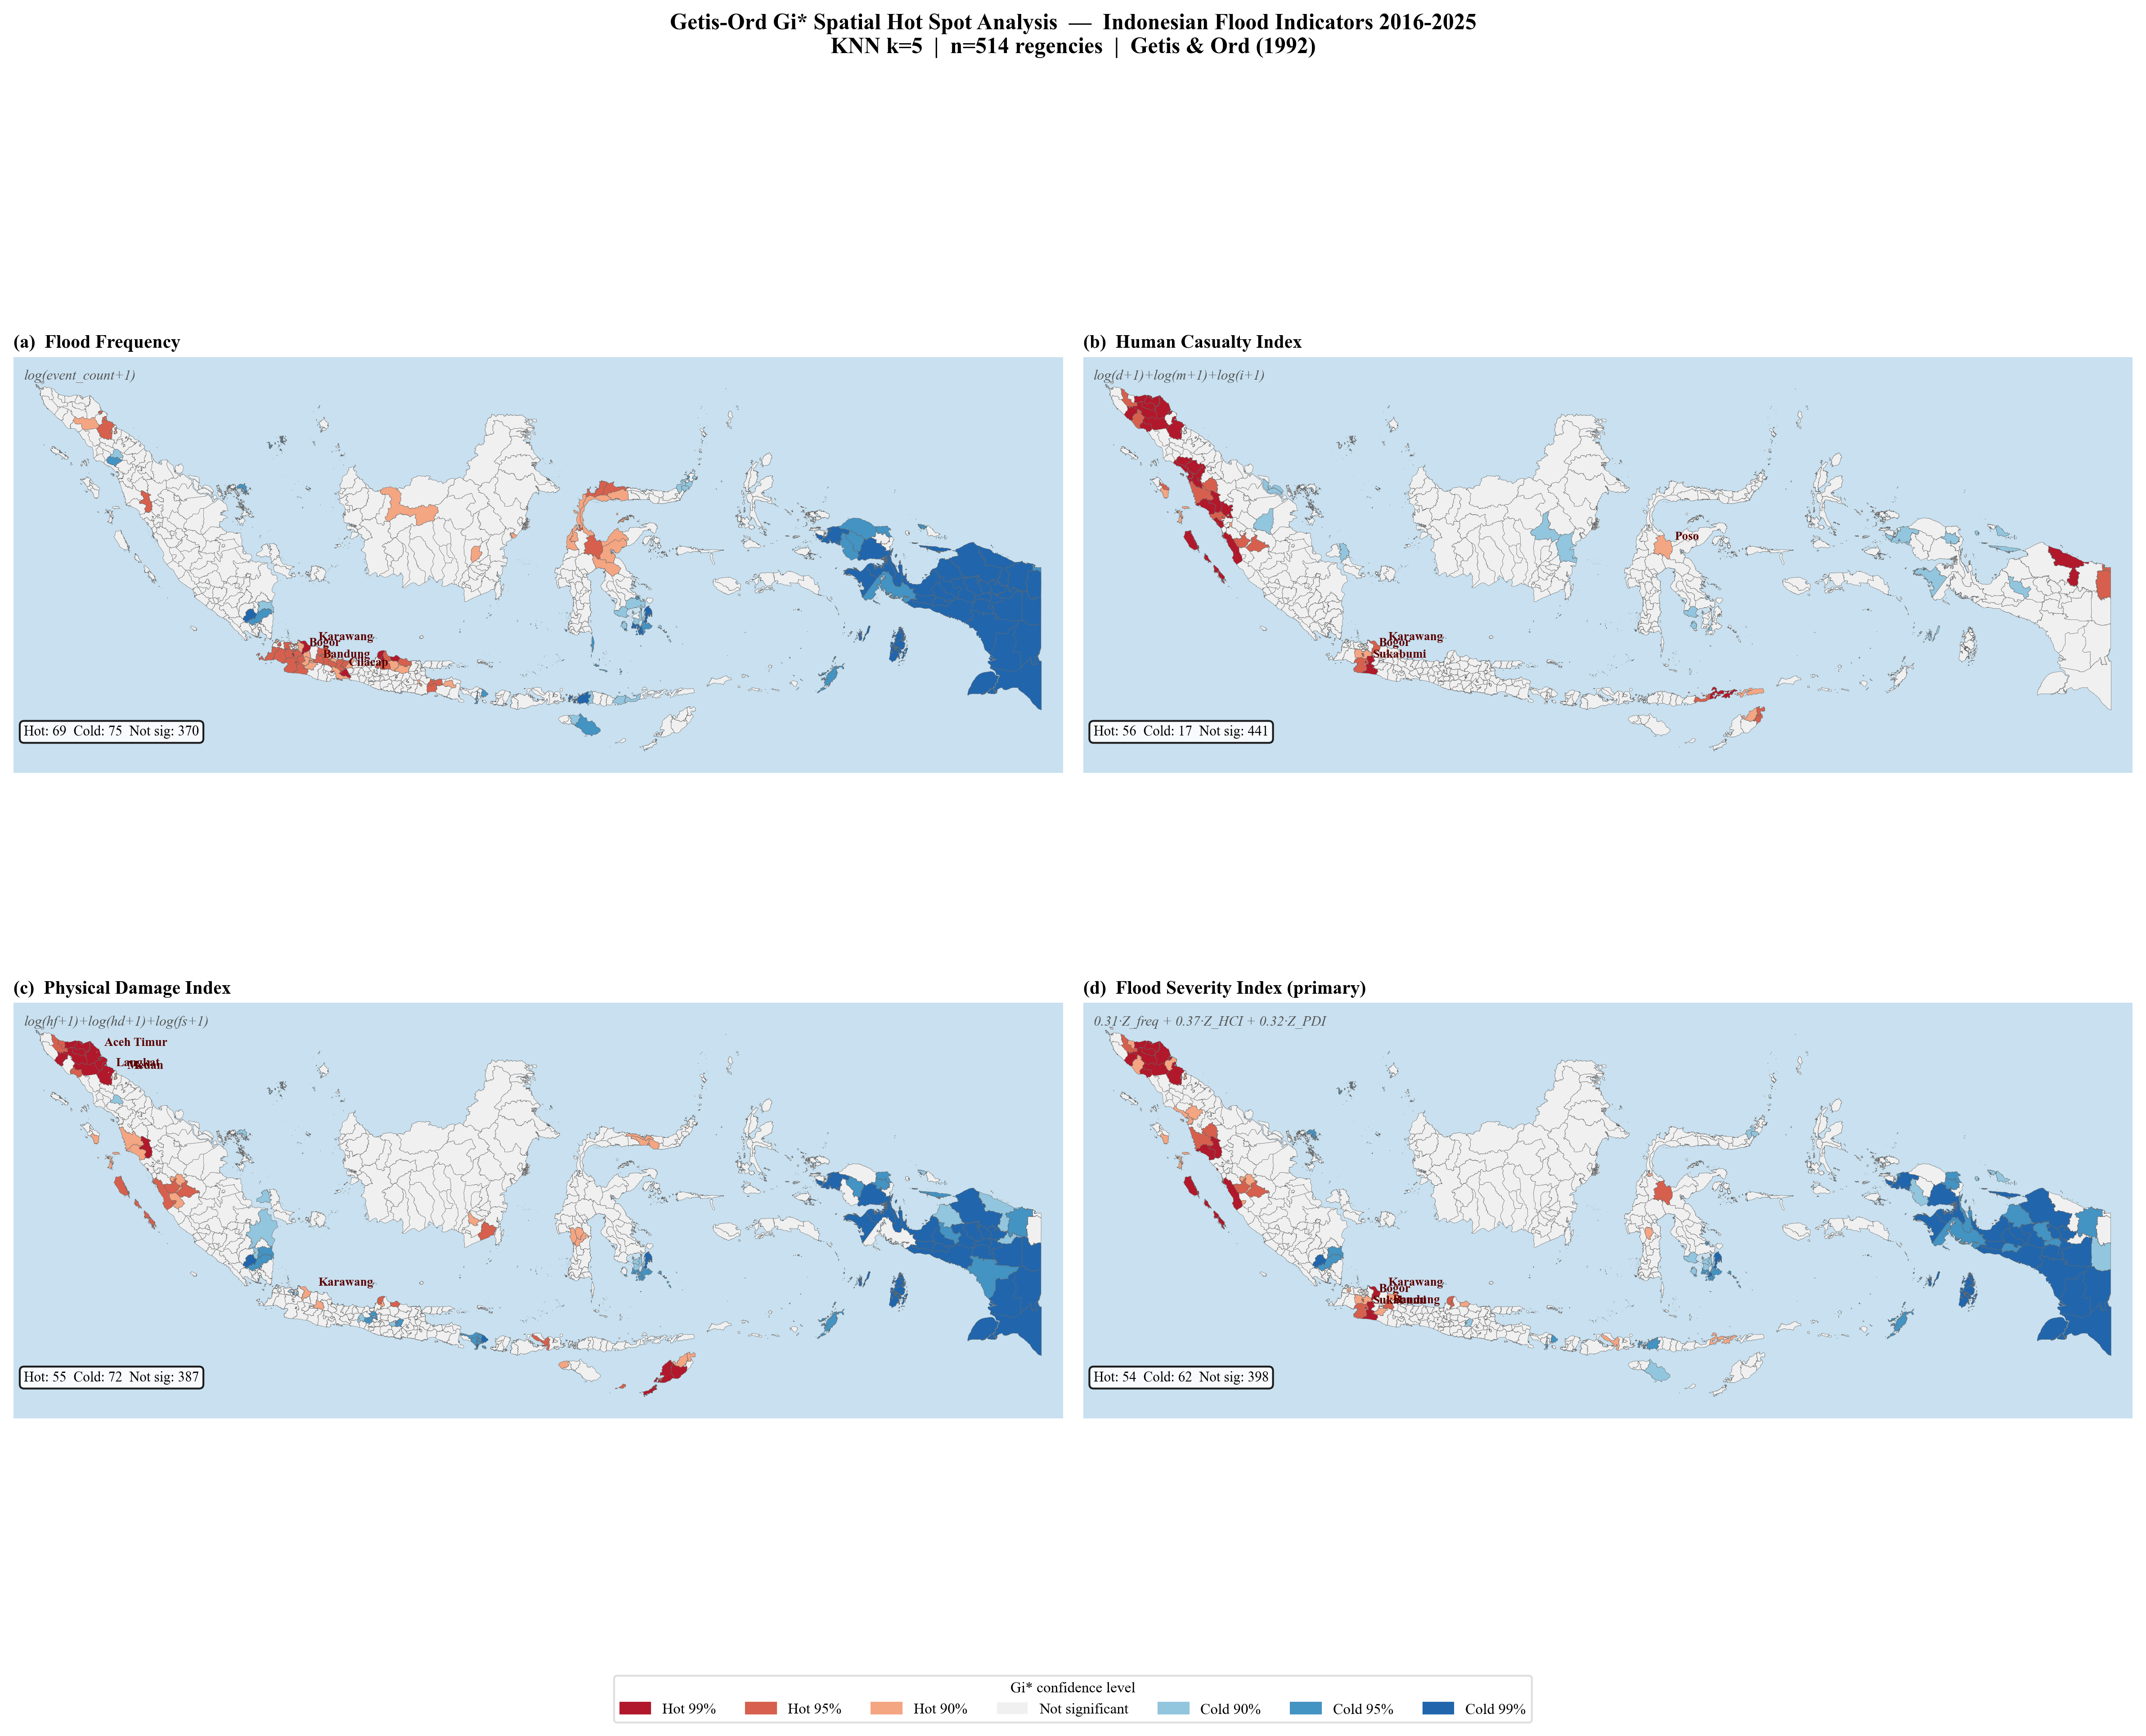

In [72]:
# ════════════════════════════════════════════════════
# STEP 6 — Figure — Getis--Ord Gi* maps
# Cite: Getis & Ord (1992) Geographical Analysis 24(3)
# ════════════════════════════════════════════════════
# plt.ioff() disables interactive canvas updates during drawing.
# This prevents geopandas sub-calls from triggering draw_idle() on every
# polygon render — the cause of the slow/KeyboardInterrupt in the old code.
# plt.ion() re-enables interactivity so plt.show() displays inline.

plt.ioff()
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()
fig.suptitle(
    'Getis-Ord Gi* Spatial Hot Spot Analysis  —  Indonesian Flood Indicators 2016-2025\n'
    f'KNN k=5  |  n={N} regencies  |  Getis & Ord (1992)',
    fontsize=12, fontweight='bold', y=1.02
)

# And update gi_cfg:
gi_cfg = {
    'event_count': ('(a)  Flood Frequency',  'log(event_count+1)'),
    'HCI'        : ('(b)  Human Casualty Index', 'log(d+1)+log(m+1)+log(i+1)'),
    'PDI'        : ('(c)  Physical Damage Index', 'log(hf+1)+log(hd+1)+log(fs+1)'),
    'FSI'        : ('(d)  Flood Severity Index (primary)',
                    f'{w_freq:.2f}·Z_freq + {w_HCI:.2f}·Z_HCI + {w_PDI:.2f}·Z_PDI'),
}

for ax, dim in zip(axes, DIMS):
    title, formula = gi_cfg[dim]
    map_frame(ax, title, formula)
    draw_cat(ax, f'gi_cat_{dim}', GI_COLORS)
    annotate_top(ax, f'gi_cat_{dim}', n=4)
    gc = flood[f'gi_cat_{dim}']
    nhot = gc.str.startswith('Hot').sum()
    ncld = gc.str.startswith('Cold').sum()
    ax.text(0.01,0.09, f'Hot: {nhot}  Cold: {ncld}  Not sig: {N-nhot-ncld}',
            transform=ax.transAxes, fontsize=7.5,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.88))

leg = ([mpatches.Patch(color=GI_COLORS[k], label=k)
        for k in ['Hot 99%','Hot 95%','Hot 90%']] +
       [mpatches.Patch(color='#f0f0f0', label='Not significant',
                       edgecolor='#ccc', linewidth=0.5)] +
       [mpatches.Patch(color=GI_COLORS[k], label=k)
        for k in ['Cold 90%','Cold 95%','Cold 99%']])
fig.legend(handles=leg, loc='lower center', ncol=7, fontsize=8,
           bbox_to_anchor=(0.5,-0.04), framealpha=0.95, edgecolor='#ddd',
           title='Gi* confidence level', title_fontsize=8)
plt.tight_layout()
plt.ion(); plt.show()


## STEP 7 — Figure — FSI choropleth versus hot-spot comparison

Produce the side-by-side comparison of the FSI choropleth and the FSI hot-spot classification.

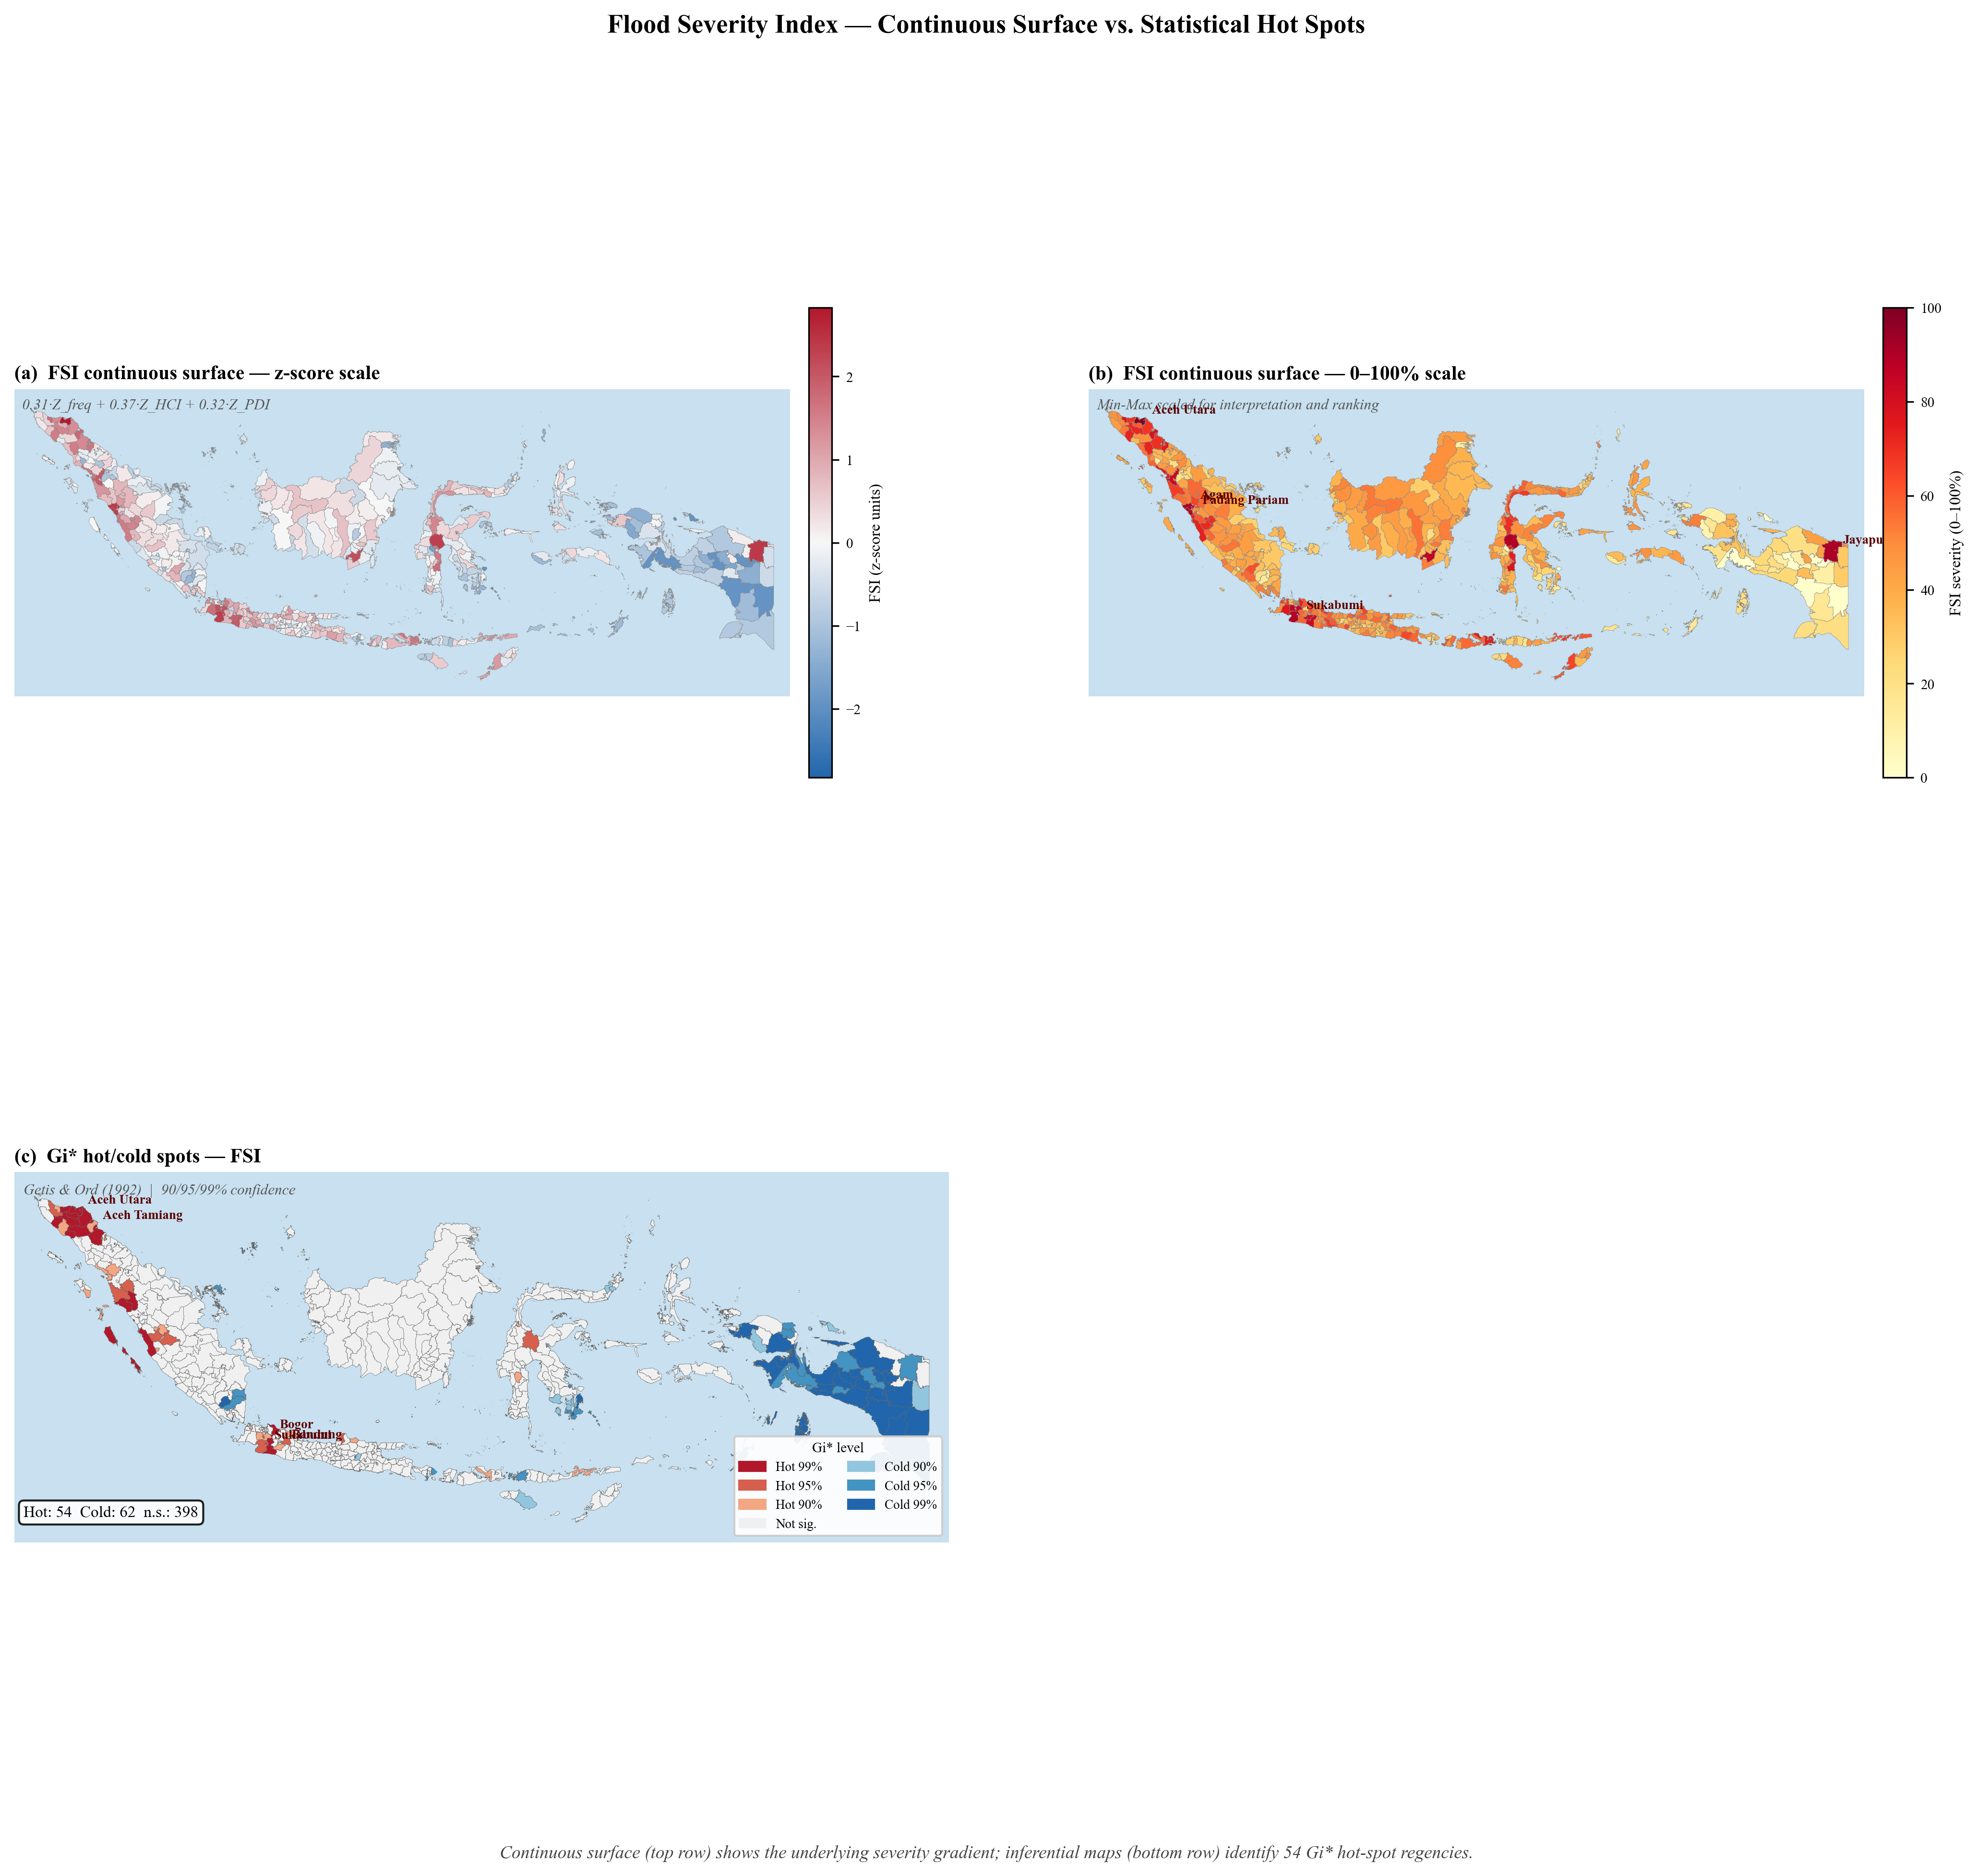

In [74]:
# ═══════════════════════════════════════════════════════════════
# STEP 7 — Figure — FSI choropleth versus hot-spot comparison
# ═══════════════════════════════════════════════════════════════
# Side-by-side comparison of the continuous Flood Severity Index
# and the inferential hot-spot identification (Gi*).
#
# Top row    — what the FSI looks like (continuous gradient)
# Bottom row — where clustering is statistically significant
#
# This layout lets the reader visually verify that statistically
# significant hot spots correspond to the high-FSI regions of the
# continuous surface, validating the inference.
# ═══════════════════════════════════════════════════════════════

plt.ioff()
fig = plt.figure(figsize=(18, 13))
fig.suptitle('Flood Severity Index — Continuous Surface vs. Statistical Hot Spots',
             fontsize=13, fontweight='bold', y=0.995)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.30, wspace=0.15,
                       height_ratios=[1, 1])

cmap_div = LinearSegmentedColormap.from_list('div', ['#2166ac','#f7f7f7','#b2182b'])

# ─────────────────────────────────────────────────────────────────────────
# TOP-LEFT (a) — FSI choropleth in z-score units (statistical scale)
# ─────────────────────────────────────────────────────────────────────────
ax_a = fig.add_subplot(gs[0, 0])
map_frame(ax_a,
          '(a)  FSI continuous surface — z-score scale',
          f'{w_freq:.2f}·Z_freq + {w_HCI:.2f}·Z_HCI + {w_PDI:.2f}·Z_PDI')
fsi_v = flood['FSI'].values
vmax  = max(abs(fsi_v.min()), abs(fsi_v.max()))
norm_z = Normalize(vmin=-vmax, vmax=vmax)

if USE_POLY:
    mg = gdf.merge(flood[['bps_kab_code','FSI']], on='bps_kab_code', how='left')
    mg.plot(column='FSI', ax=ax_a, cmap=cmap_div, norm=norm_z,
            linewidth=0.15, edgecolor='#888', missing_kwds={'color':'#eee'})
else:
    ax_a.scatter(LON, LAT, c=fsi_v, cmap=cmap_div, norm=norm_z,
                 s=28, alpha=0.85, linewidths=0)
cb_a = fig.colorbar(plt.cm.ScalarMappable(norm=norm_z, cmap=cmap_div),
                    ax=ax_a, shrink=0.75, pad=0.02)
cb_a.set_label('FSI (z-score units)', fontsize=8); cb_a.ax.tick_params(labelsize=7)

# ─────────────────────────────────────────────────────────────────────────
# TOP-RIGHT (b) — FSI choropleth in 0–100% scale (interpretive)
# ─────────────────────────────────────────────────────────────────────────
ax_b = fig.add_subplot(gs[0, 1])
map_frame(ax_b,
          '(b)  FSI continuous surface — 0–100% scale',
          'Min-Max scaled for interpretation and ranking')
fsi_pct = flood['FSI_index'].values
cmap_seq = plt.cm.YlOrRd
norm_pct = Normalize(vmin=0, vmax=100)

if USE_POLY:
    mg = gdf.merge(flood[['bps_kab_code','FSI_index']], on='bps_kab_code', how='left')
    mg.plot(column='FSI_index', ax=ax_b, cmap=cmap_seq, norm=norm_pct,
            linewidth=0.15, edgecolor='#888', missing_kwds={'color':'#eee'})
else:
    ax_b.scatter(LON, LAT, c=fsi_pct, cmap=cmap_seq, norm=norm_pct,
                 s=28, alpha=0.85, linewidths=0)
cb_b = fig.colorbar(plt.cm.ScalarMappable(norm=norm_pct, cmap=cmap_seq),
                    ax=ax_b, shrink=0.75, pad=0.02)
cb_b.set_label('FSI severity (0–100%)', fontsize=8); cb_b.ax.tick_params(labelsize=7)

# Annotate top-5 most severe regencies on percent map
top_pct = flood.nlargest(5, 'FSI_index')
for _, row in top_pct.iterrows():
    name = row['bps_kab_name'].replace('Kab. ','').replace('Kota ','')[:13]
    ax_b.annotate(name, (row['centroid_lon'], row['centroid_lat']),
                  xytext=(6, 4), textcoords='offset points',
                  fontsize=6.5, color='#5c0000', fontweight='bold',
                  arrowprops=dict(arrowstyle='-', color='#bbb', lw=0.4))

# ─────────────────────────────────────────────────────────────────────────
# BOTTOM-LEFT (c) — Gi* hot/cold spots on FSI
# ─────────────────────────────────────────────────────────────────────────
ax_c = fig.add_subplot(gs[1, 0])
map_frame(ax_c,
          '(c)  Gi* hot/cold spots — FSI',
          'Getis & Ord (1992)  |  90/95/99% confidence')
draw_cat(ax_c, 'gi_cat_FSI', GI_COLORS)
top_hot = flood[flood['gi_cat_FSI'].str.startswith('Hot')].nlargest(5, 'FSI')
for _, row in top_hot.iterrows():
    name = row['bps_kab_name'].replace('Kab. ','').replace('Kota ','')[:13]
    ax_c.annotate(name, (row['centroid_lon'], row['centroid_lat']),
                  xytext=(6, 4), textcoords='offset points',
                  fontsize=6.5, color='#5c0000', fontweight='bold',
                  arrowprops=dict(arrowstyle='-', color='#bbb', lw=0.4))
gc_c = flood['gi_cat_FSI']
ax_c.text(0.01, 0.07,
          f'Hot: {gc_c.str.startswith("Hot").sum()}  '
          f'Cold: {gc_c.str.startswith("Cold").sum()}  '
          f'n.s.: {(gc_c=="Not sig.").sum()}',
          transform=ax_c.transAxes, fontsize=8,
          bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.88))

# Compact legend for Gi*
gi_handles = ([mpatches.Patch(color=GI_COLORS[k], label=k)
               for k in ['Hot 99%','Hot 95%','Hot 90%']] +
              [mpatches.Patch(color='#f0f0f0', label='Not sig.',
                               edgecolor='#ccc', linewidth=0.5)] +
              [mpatches.Patch(color=GI_COLORS[k], label=k)
               for k in ['Cold 90%','Cold 95%','Cold 99%']])
ax_c.legend(handles=gi_handles, loc='lower right', fontsize=6.5,
            framealpha=0.92, ncol=2, title='Gi* level', title_fontsize=7)

# ─────────────────────────────────────────────────────────────────────────
# Caption / interpretive footer (axis-level text below all panels)
# ─────────────────────────────────────────────────────────────────────────
n_hot = flood['gi_cat_FSI'].str.startswith('Hot').sum()
fig.text(0.5, 0.01,
         f'Continuous surface (top row) shows the underlying severity gradient; '
         f'inferential maps (bottom row) identify {n_hot} Gi* hot-spot regencies.',
         ha='center', fontsize=9, style='italic', color='#444')

plt.tight_layout(rect=[0, 0.025, 1, 0.985])
plt.ion(); plt.show()

## STEP 8 — Conclusions — local spatial clustering (H01)

Summarise the local spatial-clustering evidence for the first null hypothesis.

In [76]:
# ═══════════════════════════════════════════════
# STEP 8 — Conclusions — local spatial clustering (H01)
# ═══════════════════════════════════════════════

print('=' * 70)
print('H\u2080\u2081 LOCAL SPATIAL ANALYSIS — CONCLUSIONS')
print('=' * 70)
print(f'\nMethod: Getis-Ord Gi* (local hot-spot statistic)')
print(f'Data:   Indonesian flood records 2016\u20132025  |  n = {N} regencies')
print(f'W:      KNN k = {KNN_K}  |  binary weights for Gi*')

# ─── Per-dimension summary table ──────────────────────────────────────
print('\n' + '─' * 40)
print(f'{"Dimension":<18} {"Gi* Hot":>8} {"Gi* Cold":>9}')
print('─' * 40)
for dim in DIMS:
    gc = flood[f'gi_cat_{dim}']
    label = {'event_count':'Frequency',
             'HCI':'HCI (human)',
             'PDI':'PDI (physical)',
             'FSI':'FSI (PRIMARY)'}[dim]
    print(f'{label:<18} '
          f'{gc.str.startswith("Hot").sum():>8} '
          f'{gc.str.startswith("Cold").sum():>9}')

# ─── FSI hot spots (primary identification) ───────────────────────────
print('\n' + '═' * 70)
print('PRIMARY HEADLINE FINDING (FSI integrated measure)')
print('═' * 70)
gc_fsi = flood['gi_cat_FSI']
n_hot  = gc_fsi.str.startswith('Hot').sum()
n_cold = gc_fsi.str.startswith('Cold').sum()
print(f'  FSI hot spots (Gi*):   {n_hot}')
print(f'  FSI cold spots (Gi*):  {n_cold}')

# ─── Top-10 FSI hot spots by Gi* z-score ──────────────────────────────
print('\n' + '═' * 70)
print('TOP-10 FSI HOT SPOTS (Gi* significant, ranked by z-score)')
print('═' * 70)
top_hot = (flood[flood['gi_cat_FSI'].str.startswith('Hot')]
           .sort_values('gi_z_FSI', ascending=False)
           .head(10).reset_index(drop=True))
print(f'  {"Rank":>4}  {"Regency":<32} {"Province":<22} '
      f'{"FSI":>7} {"%":>6}  {"Gi* z":>6}  {"Gi*":<10}')
print('  ' + '─' * 92)
for i, row in top_hot.iterrows():
    print(f'  {i+1:>4}  {row["bps_kab_name"][:32]:<32} {row["bps_prov_name"][:22]:<22} '
          f'{row["FSI"]:>+7.3f} {row["FSI_index"]:>5.1f}%  '
          f'{row["gi_z_FSI"]:>6.2f}  {row["gi_cat_FSI"]:<10}')

# ─── High-FSI but not a hot spot (individually severe, spatially isolated) ──
top_fsi_codes = set(flood.nlargest(10, 'FSI')['bps_kab_code'])
hot_codes     = set(flood[flood['gi_cat_FSI'].str.startswith('Hot')]['bps_kab_code'])
isolated = top_fsi_codes - hot_codes
if isolated:
    print('\n  High-FSI regencies that are NOT Gi* hot spots')
    print('  (individually severe but spatially isolated):')
    iso = flood[flood['bps_kab_code'].isin(isolated)][
        ['bps_kab_name','bps_prov_name','FSI','gi_cat_FSI']]
    for _, row in iso.iterrows():
        print(f'    • {row["bps_kab_name"]:<35} {row["bps_prov_name"]:<22} '
              f'FSI={row["FSI"]:+.3f}  Gi*={row["gi_cat_FSI"]}')

# ─── Top cold spots (low-burden reference zones) ──────────────────────
print('\n' + '═' * 70)
print('TOP-RANKED FSI COLD-SPOT REGENCIES (low-burden reference zones)')
print('═' * 70)
top_cold = (flood[flood['gi_cat_FSI'].str.startswith('Cold')]
            .nsmallest(10, 'FSI'))
if len(top_cold) > 0:
    print(f'  {"Rank":>4}  {"Regency":<32} {"Province":<22} {"FSI":>7} {"%":>6}')
    print('  ' + '─' * 75)
    for i, (_, row) in enumerate(top_cold.iterrows()):
        print(f'  {i+1:>4}  {row["bps_kab_name"][:32]:<32} {row["bps_prov_name"][:22]:<22} '
              f'{row["FSI"]:>+7.3f} {row["FSI_index"]:>5.1f}%')
else:
    print('  No Gi* cold-spot regencies identified.')

# ─── Substantive interpretation ───────────────────────────────────────
print('\n' + '═' * 70)
print('SUBSTANTIVE INTERPRETATION')
print('═' * 70)
print(f"""
H\u2080\u2081 is REJECTED at the local level: the Getis-Ord Gi* statistic
identifies {n_hot} significant FSI hot spots and {n_cold} cold spots,
confirming statistically significant local spatial clustering of flood
severity.

The hot spots are the priority zones for regional flood disaster risk
reduction policy: they and their neighbours share elevated burden,
indicating regional rather than isolated concentrations. High-FSI
regencies that are not Gi* hot spots are individually severe but
spatially isolated, warranting targeted rather than regional response.

CONVERGENCE WITH THE GLOBAL ANALYSIS
────────────────────────────────────
The Global Moran's I established that overall spatial clustering exists;
this local Gi* analysis localises that finding to the specific regencies
driving it, providing the empirical basis for the spatial interpretation
of RQ1.
""")


H₀₁ LOCAL SPATIAL ANALYSIS — CONCLUSIONS

Method: Getis-Ord Gi* (local hot-spot statistic)
Data:   Indonesian flood records 2016–2025  |  n = 514 regencies
W:      KNN k = 5  |  binary weights for Gi*

────────────────────────────────────────
Dimension           Gi* Hot  Gi* Cold
────────────────────────────────────────
Frequency                69        75
HCI (human)              56        17
PDI (physical)           55        72
FSI (PRIMARY)            54        62

══════════════════════════════════════════════════════════════════════
PRIMARY HEADLINE FINDING (FSI integrated measure)
══════════════════════════════════════════════════════════════════════
  FSI hot spots (Gi*):   54
  FSI cold spots (Gi*):  62

══════════════════════════════════════════════════════════════════════
TOP-10 FSI HOT SPOTS (Gi* significant, ranked by z-score)
══════════════════════════════════════════════════════════════════════
  Rank  Regency                          Province                   FSI     

## STEP 9 — Export — master workbook

Export the master workbook: the single source of truth for the FSI, clusters, and spatial results used by Notebooks 7-12.

In [78]:
# ═══════════════════════════════════════════════════════════════════════════
# STEP 9 — Export — master workbook
# ═══════════════════════════════════════════════════════════════════════════
# This Excel is the contract between nb6 (canonical pipeline) and the
# downstream consumers. Sheets:
#   1_Cumulative         — 514 regencies × all index + spatial-stat columns
#   2_Annual_Panel       — 5,140 rows × indices (no spatial stats; nb7 input)
#   3_Methodology        — formulas, FSI weights, references
#   4_High_Severity_FSI — high-severity FSI regencies (FSI top tier) ranked
#   5_Dimension_Summary  — cluster counts per dimension
# ═══════════════════════════════════════════════════════════════════════════

import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter

OUTPUT_XLSX = '../data/processed/6_flood_master.xlsx'

# ─── Build the cumulative master DataFrame ────────────────────────────
base_cols = ['bps_kab_code', 'bps_kab_name', 'bps_prov_name',
             'centroid_lat', 'centroid_lon',
             'event_count', 'deaths', 'missing', 'injured',
             'house_flooded', 'house_damaged', 'fasum_damaged']

composite_cols = ['log_event', 'HCI', 'PDI',
                  'Z_freq', 'Z_HCI', 'Z_PDI']

fsi_cols = ['FSI', 'FSI_index', 'cluster']

def severity_tier(p):
    if p < 25:  return 'Low'
    if p < 50:  return 'Moderate'
    if p < 75:  return 'High'
    return 'Catastrophic'
# FSI_tier removed — avoided naming conflict with the K-means cluster labels.
# fsi_top_tier preserved as boolean flag for top-25% severity identification.
# severity_tier() function below still applied to compute the flag.

gi_cols   = [f'gi_z_{d}'      for d in DIMS] + \
            [f'gi_cat_{d}'    for d in DIMS]
# Gi* and Moran scatter (mz/mwz) retained for spatial autocorrelation reporting.
moran_cols = [f'mz_{d}'  for d in DIMS] + \
             [f'mwz_{d}' for d in DIMS]

# ── fsi_top_tier: severity threshold (NOT a spatial test) ──────────
# RENAMED from 'confirmed_hot_FSI' (which was misleading — it sounded
# like a Gi* significance flag). This column is simply:
#     fsi_top_tier == True   iff   FSI_tier == 'Catastrophic'
#                            iff   FSI_index >= 75
# It is a SEVERITY THRESHOLD on the min-max scaled FSI distribution.
# For STATISTICAL hot-spot identification, use `gi_cat_FSI` directly
# (categories: 'Hot 99%', 'Hot 95%', 'Hot 90%', or 'Not sig.').
#
# Note on count: because FSI is right-skewed, the Catastrophic tier
# captures ~3.7% of regencies (not 25%) — the threshold is on the
# 0–100 scale of observed severity, not a quartile rank.
flood['fsi_top_tier'] = (flood['FSI_index'] >= 75)

# For non-FSI dimensions, derive an analogous severity-threshold flag:
# regencies in the top 25% of the dimension's Moran z-score distribution.
for dim in [d for d in DIMS if d != 'FSI']:
    col = f'mz_{dim}' if f'mz_{dim}' in flood.columns else dim
    threshold = flood[col].quantile(0.75)
    flood[f'{dim}_top_tier'] = flood[col] >= threshold

# Names retained as a single list for export (used below)
tier_flag_cols = ['fsi_top_tier'] + [
    f'{d}_top_tier' for d in DIMS if d != 'FSI'
]

cumulative = flood[
    base_cols + composite_cols + fsi_cols +
    gi_cols + moran_cols + tier_flag_cols
].copy()

for c in cumulative.select_dtypes(include=[np.number]).columns:
    if c not in ['bps_kab_code', 'cluster']:
        cumulative[c] = cumulative[c].round(4)

print(f'1_Cumulative table: {cumulative.shape[0]} regencies × {cumulative.shape[1]} columns')

# ─── Build annual panel sheet ─────────────────────────────────────────
ANN_COLS = [
    'bps_kab_code', 'bps_kab_name', 'bps_prov_name',
    'centroid_lat', 'centroid_lon',          # cross-sectional, repeated per year — needed by nb7 Step 5
    'year',
    'event_count', 'deaths', 'missing', 'injured',
    'house_flooded', 'house_damaged', 'fasum_damaged',
    'log_event', 'HCI', 'PDI',
    'Z_freq', 'Z_HCI', 'Z_PDI',
    'FSI', 'FSI_index',
]
annual_out = annual[ANN_COLS].copy()
for c in annual_out.select_dtypes(include=[np.number]).columns:
    if c not in ['bps_kab_code', 'year']:
        annual_out[c] = annual_out[c].round(4)
print(f'2_Annual_Panel table: {annual_out.shape[0]:,} rows × {annual_out.shape[1]} columns')

# ─── Priority hot-spot summary ────────────────────────────────────────
priority = flood[flood['fsi_top_tier']].copy()
priority = priority[
    ['bps_kab_code','bps_kab_name','bps_prov_name',
     'centroid_lat','centroid_lon',
     'event_count','deaths','injured','house_flooded',
     'FSI','FSI_index','cluster',
     'gi_z_FSI','gi_cat_FSI']
].sort_values('FSI', ascending=False).reset_index(drop=True)
priority.insert(0, 'rank', priority.index + 1)
print(f'4_High_Severity_FSI: {len(priority)} high-severity FSI regencies (FSI top tier)')

# ─── Per-dimension summary ────────────────────────────────────────────
summary_rows = []
for dim in DIMS:
    gc = flood[f'gi_cat_{dim}']
    # Top-tier flag name depends on dim (renamed for FSI to avoid
    # misleading 'confirmed_hot' label)
    flag_col = 'fsi_top_tier' if dim == 'FSI' else f'{dim}_top_tier'
    confirmed = flood[flag_col].sum()
    summary_rows.append({
        'Dimension'         : dim,
        'Gi*_Hot_99'        : (gc=='Hot 99%').sum(),
        'Gi*_Hot_95'        : (gc=='Hot 95%').sum(),
        'Gi*_Hot_90'        : (gc=='Hot 90%').sum(),
        'Gi*_Hot_total'     : gc.str.startswith('Hot').sum(),
        'Gi*_Cold_total'   : gc.str.startswith('Cold').sum(),
        'Top_tier'    : confirmed,
        'Pct_Gi_signif'    : round(((gc != 'Not sig.') & gc.notna()).mean() * 100, 1),
    })
df_summary = pd.DataFrame(summary_rows)

# ─── Methodology sheet ────────────────────────────────────────────────
methodology_rows = [
    ('Field', 'Value'),
    ('Notebook',                  'nb6 — Canonical pipeline + master Excel exporter'),
    ('Purpose',                   'Single source of truth for HCI, PDI, FSI definitions'),
    ('Period',                    f'{YEARS[0]}-{YEARS[-1]}'),
    ('Unit',                      'Regency (kabupaten/kota)'),
    ('N regencies (cumulative)',  str(N)),
    ('N rows (annual panel)',     str(len(annual_out))),
    ('',                          ''),
    ('HCI formula',               'log(deaths+1) + log(missing+1) + log(injured+1)'),
    ('PDI formula',               'log(houses_flooded+1) + log(houses_damaged+1) + log(fasum_damaged+1)'),
    ('Z-score',                   '(x - mean) / std'),
    ('',                          ''),
    ('FSI formula',               f'{w_freq:.4f}·Z_freq + {w_HCI:.4f}·Z_HCI + {w_PDI:.4f}·Z_PDI'),
    ('FSI weight method',         'η² from k-means clustering (k=3)'),
    ('w_freq',                    f'{w_freq:.4f}'),
    ('w_HCI',                     f'{w_HCI:.4f}'),
    ('w_PDI',                     f'{w_PDI:.4f}'),
    ('FSI_index',               'Min-max scaled FSI to 0-100 (visualisation)'),
    ('',                          ''),
    ('FSI tier thresholds',       'Low <25, Moderate 25-50, High 50-75, Catastrophic ≥75'),
    ('',                          ''),
    ('Cumulative Z-score basis',  'Across all 514 regencies (single pool)'),
    ('Annual Z-score basis',      'Within-year (each year standardised independently)'),
    ('',                          ''),
    ('Spatial weights',           f'KNN k={KNN_K}'),
    ('  W for Gi*',               'Binary KNN'),
    ('FSI top-tier flag',         'fsi_top_tier := (FSI_index >= 75)  (top 25% severity)'),
    ('  Semantics',               'SEVERITY threshold (FSI_index ≥ 75), NOT a spatial test'),
    ('  For statistical hot spots', 'Use gi_cat_FSI directly (Hot 90%/95%/99%)'),
    ('',                          ''),
    ('References',                ''),
    ('  Getis & Ord (1992)',      'The analysis of spatial association by use of distance statistics. Geographical Analysis 24(3), 189-206.'),
    ('  Hallegatte (2014)',       'Natural Disasters and Climate Change. Springer.'),
    ('  Noy & Vu (2010)',         'The economics of natural disasters in a developing country: The case of Vietnam. JAE 21(4).'),
    ('  Cutter et al. (2003)',    'Social vulnerability to environmental hazards. SSQ 84(2).'),
    ('  OECD (2008)',             'Handbook on Constructing Composite Indicators.'),
]
df_methods = pd.DataFrame(methodology_rows[1:], columns=methodology_rows[0])

# ─── Helper: styled write to worksheet ────────────────────────────────
def write_styled(ws, df, title=None):
    BLUE  = PatternFill('solid', fgColor='0C447C')
    WHITE = Font(color='FFFFFF', bold=True, size=10)
    BODY  = Font(size=10)
    GREEN = PatternFill('solid', fgColor='E8F5E9')
    AMBER = PatternFill('solid', fgColor='FFF8E1')
    THIN  = Border(left=Side(style='thin'), right=Side(style='thin'),
                   top=Side(style='thin'),  bottom=Side(style='thin'))
    start = 3 if title else 1
    if title:
        c = ws.cell(row=1, column=1, value=title)
        c.font = Font(bold=True, size=12, color='0C447C')
    for ci, col in enumerate(df.columns, 1):
        c = ws.cell(row=start, column=ci, value=str(col))
        c.fill = BLUE; c.font = WHITE; c.border = THIN
        c.alignment = Alignment(horizontal='center', wrap_text=True)
    for ri, (_, row) in enumerate(df.iterrows(), start + 1):
        for ci, col in enumerate(df.columns, 1):
            v = row[col]
            v = None if (pd.isna(v) if not isinstance(v, (str, bool)) else False) else v
            c = ws.cell(row=ri, column=ci, value=v)
            c.font = BODY; c.border = THIN
            # Highlight rows by FSI severity (fsi_top_tier flag from FSI_index)
            if 'fsi_top_tier' in df.columns:
                if row.get('fsi_top_tier') is True:
                    c.fill = GREEN
                elif row.get('FSI_index', 0) >= 50:
                    c.fill = AMBER
    for ci in range(1, len(df.columns) + 1):
        vals = [str(ws.cell(row=r, column=ci).value or '')
                for r in range(start, ws.max_row + 1)]
        ws.column_dimensions[get_column_letter(ci)].width = min(
            max((len(v) for v in vals), default=8) + 2, 40)
    ws.freeze_panes = ws.cell(row=start + 1, column=1)
    ws.auto_filter.ref = ws.dimensions

# ─── Write workbook ───────────────────────────────────────────────────
wb = openpyxl.Workbook()
wb.remove(wb.active)

write_styled(
    wb.create_sheet('1_Cumulative'),
    cumulative,
    f'Cumulative regency-level master ({N} regencies). Index columns + Gi* + hot-spot flags.'
)

write_styled(
    wb.create_sheet('2_Annual_Panel'),
    annual_out,
    f'Annual flood panel ({len(annual_out):,} rows = {N} regencies × {len(YEARS)} years). '
    f'For Mann-Kendall trend analysis (nb7).'
)

write_styled(
    wb.create_sheet('3_Methodology'),
    df_methods,
    'Methodology — canonical formulas, weights, references'
)

write_styled(
    wb.create_sheet('4_High_Severity_FSI'),
    priority,
    f'High-severity FSI regencies — {len(priority)} top-tier FSI regencies, ranked by FSI'
)

write_styled(
    wb.create_sheet('5_Dimension_Summary'),
    df_summary,
    'Per-dimension summary — Gi* cluster counts'
)

wb.save(OUTPUT_XLSX)

import os
print(f'\n  ✓ Master Excel exported → {OUTPUT_XLSX}')
print(f'      Size: {os.path.getsize(OUTPUT_XLSX) / 1024:,.0f} KB')
print(f'\n  Sheets:')
for name in wb.sheetnames:
    print(f'    • {name}')

print(f"""
  DOWNSTREAM USAGE
  ────────────────
  At the top of nb7, nb8, nb9, replace inline FSI/HCI/PDI builds with:

      MASTER_PATH = '{OUTPUT_XLSX}'
      flood   = pd.read_excel(MASTER_PATH, sheet_name='1_Cumulative',     skiprows=2)
      annual  = pd.read_excel(MASTER_PATH, sheet_name='2_Annual_Panel',   skiprows=2)
      meth    = pd.read_excel(MASTER_PATH, sheet_name='3_Methodology',    skiprows=2)
      priority= pd.read_excel(MASTER_PATH, sheet_name='4_High_Severity_FSI', skiprows=2)

  No downstream notebook should recompute HCI, PDI, FSI, or FSI weights.
  All downstream calculations use these pre-computed canonical values.
""")


1_Cumulative table: 514 regencies × 41 columns
2_Annual_Panel table: 5,140 rows × 21 columns
4_High_Severity_FSI: 19 high-severity FSI regencies (FSI top tier)

  ✓ Master Excel exported → ../data/processed/6_flood_master.xlsx
      Size: 572 KB

  Sheets:
    • 1_Cumulative
    • 2_Annual_Panel
    • 3_Methodology
    • 4_High_Severity_FSI
    • 5_Dimension_Summary

  DOWNSTREAM USAGE
  ────────────────
  At the top of nb7, nb8, nb9, replace inline FSI/HCI/PDI builds with:

      MASTER_PATH = '../data/processed/6_flood_master.xlsx'
      flood   = pd.read_excel(MASTER_PATH, sheet_name='1_Cumulative',     skiprows=2)
      annual  = pd.read_excel(MASTER_PATH, sheet_name='2_Annual_Panel',   skiprows=2)
      meth    = pd.read_excel(MASTER_PATH, sheet_name='3_Methodology',    skiprows=2)
      priority= pd.read_excel(MASTER_PATH, sheet_name='4_High_Severity_FSI', skiprows=2)

  No downstream notebook should recompute HCI, PDI, FSI, or FSI weights.
  All downstream calculations use these

## STEP 10 — Manuscript table — Gi* top-10 hot spots

Export `table5_gi_top10_hotspots.tex` and the full hot-spot / cold-spot supplementary workbook.

In [80]:
# ============================================================================
# STEP 10 — Manuscript table — Gi* top-10 hot spots
# (full, supplementary comparison: hotspot + coldspot sheets)
# Place at the end of nb6, AFTER STEP 3 (Gi*) and after cell 1 (cluster merge
# from nb5) have both been run.
# Outputs:
#   - ../figures/table5_gi_top10_hotspots.tex          (main text, \input this)
#   - ../data/processed/appendix_hotspot_coldspot_fsi.xlsx (supplementary)
# ============================================================================
import pandas as pd
from pathlib import Path

FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = Path("../data/processed")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Map the integer cluster code (from nb5) to readable labels and numeric codes:
# 1: Catastrophic, 2: Frequent-Contained, 3: Low Impact
# ----------------------------------------------------------------------------
CLUSTER_LABELS = {0: "Low Impact", 1: "Catastrophic", 2: "Frequent-Contained"}
CLUSTER_TO_NUM = {"Catastrophic": 1, "Frequent-Contained": 2, "Low Impact": 3}

assert "flood" in dir(), "flood dataframe not found -- run earlier nb6 steps first."
assert "cluster" in flood.columns, (
    "flood['cluster'] not found -- run nb6 cell 1 (cluster merge from nb5) first."
)

flood["cluster_label"] = flood["cluster"].map(CLUSTER_LABELS)
flood["cluster_num"] = flood["cluster_label"].map(CLUSTER_TO_NUM)

# ============================================================================
# FSI hot spots AND cold spots — SORTED BY Gi* z-score
# Hotspots: Descending z-score (strongest spatial high-value clusters first)
# Coldspots: Ascending z-score (strongest spatial low-value clusters first)
# ============================================================================
hotspots_df = flood[
    flood["gi_cat_FSI"].str.startswith("Hot")
].sort_values("gi_z_FSI", ascending=False).copy()

coldspots_df = flood[
    flood["gi_cat_FSI"].str.startswith("Cold")
].sort_values("gi_z_FSI", ascending=True).copy()

assert len(hotspots_df) > 0, (
    "hotspots_df is empty -- run nb6 STEP 3 (Compute Gi*) before this cell."
)

print(f"FSI hot spots  (Gi* Hot,  any confidence level): {len(hotspots_df)}")
print(f"FSI cold spots (Gi* Cold, any confidence level): {len(coldspots_df)}")
print()
print("FSI hot spots by K-means cluster:")
print(hotspots_df["cluster_label"].value_counts().to_string())
n_catastrophic = (hotspots_df["cluster_label"] == "Catastrophic").sum()
print(f"\n-> {n_catastrophic} of {len(hotspots_df)} FSI hot spots "
      f"({n_catastrophic/len(hotspots_df):.0%}) are in the Catastrophic cluster.")


# ============================================================================
# TABLE 5 (MAIN TEXT) — Top 10 FSI hot spots by spatial intensity (Gi* z-score)
# Format: Compact Springer tabular* with Regency (Province), FSI first,
# numeric cluster (1, 2, 3), and un-indented layout + detailed footnote.
# ============================================================================
top10_hotspots = hotspots_df.head(10).copy()

def _escape_tex(s):
    """Minimal LaTeX special-character escaping."""
    return (str(s).replace("&", r"\&").replace("%", r"\%")
                  .replace("_", r"\_").replace("#", r"\#"))

tex_rows = []
for i, (_, row) in enumerate(top10_hotspots.iterrows(), start=1):
    name = _escape_tex(row["bps_kab_name"].replace("Kab. ", "").replace("Kota ", "Kota "))
    prov = _escape_tex(row["bps_prov_name"])
    reg_prov = f"{name} ({prov})"
    fsi = f"{row['FSI_index']:.1f}"
    z = f"{row['gi_z_FSI']:.2f}"
    conf = _escape_tex(row["gi_cat_FSI"])
    clus_num = row["cluster_num"]
    tex_rows.append(f"{i}  & {reg_prov:<32} & {fsi} & {z} & {conf} & {clus_num} \\\\")

tex_table = (
    r"\begin{table}[htbp]" "\n"
    r"\caption{Top 10 Flood Severity Index (FSI) hot spots ranked by local spatial intensity ($G_i^{*}$ $z$-score), 2016--2025}" "\n"
    r"\label{tab:gi_hotspots}" "\n"
    r"\centering" "\n"
    r"\footnotesize" "\n"
    r"\setlength{\tabcolsep}{0pt}" "\n"
    r"\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}clcccc@{}}" "\n"
    r"\toprule" "\n"
    r"\textbf{Rank} & \textbf{Regency (Province)} & \textbf{FSI (0--100)} & \textbf{$G_i^{*}$ $z$-score} & \textbf{Confidence} & \textbf{Cluster} \\" "\n"
    r"\midrule" "\n"
    + "\n".join(tex_rows) + "\n"
    r"\bottomrule" "\n"
    r"\end{tabular*}" "\n"
    r"\vspace{4pt}" "\n"
    r"\begin{minipage}{\textwidth}" "\n"
    r"\footnotesize\setlength{\parindent}{0pt}%" "\n"
    r"\textit{Note:} Hot spots ranked by Getis--Ord $G_i^{*}$ $z$-score based on a $k$-NN ($k=5$) spatial weight matrix (999 conditional permutations). " "\n"
    r"Cluster profiles based on K-means clustering ($k=3$): " "\n"
    r"\textbf{1} (\emph{Catastrophic}, $n=68$): characterized by exceptionally high casualties per event and severe physical damage; " "\n"
    r"\textbf{2} (\emph{Frequent-Contained}, $n=274$): characterized by high event frequency with comparatively contained casualties per event; " "\n"
    r"\textbf{3} (\emph{Low Impact}, $n=172$): characterized by low event frequency, minimal casualties, and limited infrastructure damage. " "\n"
    r"Complete hot-spot ($n=" + str(len(hotspots_df)) + r"$) and cold-spot ($n=" + str(len(coldspots_df)) + r"$) classifications across all 514 regencies are provided in Supplementary Table~S1." "\n"
    r"\end{minipage}" "\n"
    r"\end{table}" "\n"
)

out_tex = FIG_DIR / "table5_gi_top10_hotspots.tex"
out_tex.write_text(tex_table, encoding="utf-8")
print(f"\nSaved (LaTeX table): {out_tex}")
print("\n--- Preview ---")
print(tex_table)


# ============================================================================
# SUPPLEMENTARY EXCEL — Full hot spot and cold spot lists, sorted by z-score
# ============================================================================
APPENDIX_COLS = ["bps_kab_name", "bps_prov_name", "cluster_num", "cluster_label",
                 "gi_z_FSI", "gi_cat_FSI", "FSI", "FSI_index"]

appendix_hot = hotspots_df[APPENDIX_COLS].copy()
appendix_hot.insert(0, "rank_by_Gi_zscore", range(1, len(appendix_hot) + 1))

appendix_cold = coldspots_df[APPENDIX_COLS].copy()
appendix_cold.insert(0, "rank_by_Gi_zscore_ascending", range(1, len(appendix_cold) + 1))

out_xlsx = DATA_DIR / "appendix_hotspot_coldspot_fsi.xlsx"
with pd.ExcelWriter(out_xlsx, engine="openpyxl") as writer:
    appendix_hot.to_excel(writer, sheet_name="hotspots", index=False)
    appendix_cold.to_excel(writer, sheet_name="coldspots", index=False)

print(f"\nSaved (supplementary): {out_xlsx}")
print(f"  Sheet 'hotspots': {len(appendix_hot)} rows (sorted by z-score descending)")
print(f"  Sheet 'coldspots': {len(appendix_cold)} rows (sorted by z-score ascending)")

FSI hot spots  (Gi* Hot,  any confidence level): 54
FSI cold spots (Gi* Cold, any confidence level): 62

FSI hot spots by K-means cluster:
cluster_label
Frequent-Contained    30
Catastrophic          22
Low Impact             2

-> 22 of 54 FSI hot spots (41%) are in the Catastrophic cluster.

Saved (LaTeX table): ..\figures\table5_gi_top10_hotspots.tex

--- Preview ---
\begin{table}[htbp]
\caption{Top 10 Flood Severity Index (FSI) hot spots ranked by local spatial intensity ($G_i^{*}$ $z$-score), 2016--2025}
\label{tab:gi_hotspots}
\centering
\footnotesize
\setlength{\tabcolsep}{0pt}
\begin{tabular*}{\textwidth}{@{\extracolsep{\fill}}clcccc@{}}
\toprule
\textbf{Rank} & \textbf{Regency (Province)} & \textbf{FSI (0--100)} & \textbf{$G_i^{*}$ $z$-score} & \textbf{Confidence} & \textbf{Cluster} \\
\midrule
1  & Kota Lhokseumawe (Aceh)          & 51.3 & 4.36 & Hot 99\% & 2 \\
2  & Kota Langsa (Aceh)               & 46.3 & 4.26 & Hot 99\% & 2 \\
3  & Bireuen (Aceh)                   & 69.5 

## STEP 11 — Manuscript figure — Gi* hot-spot / cold-spot map

Export `fig4_gi_hotspot_map.png` (regencies coloured by Gi* category — where severity clusters spatially).

  Note: 398 regencies had an unrecognised gi_cat_FSI value: ['Not sig.']


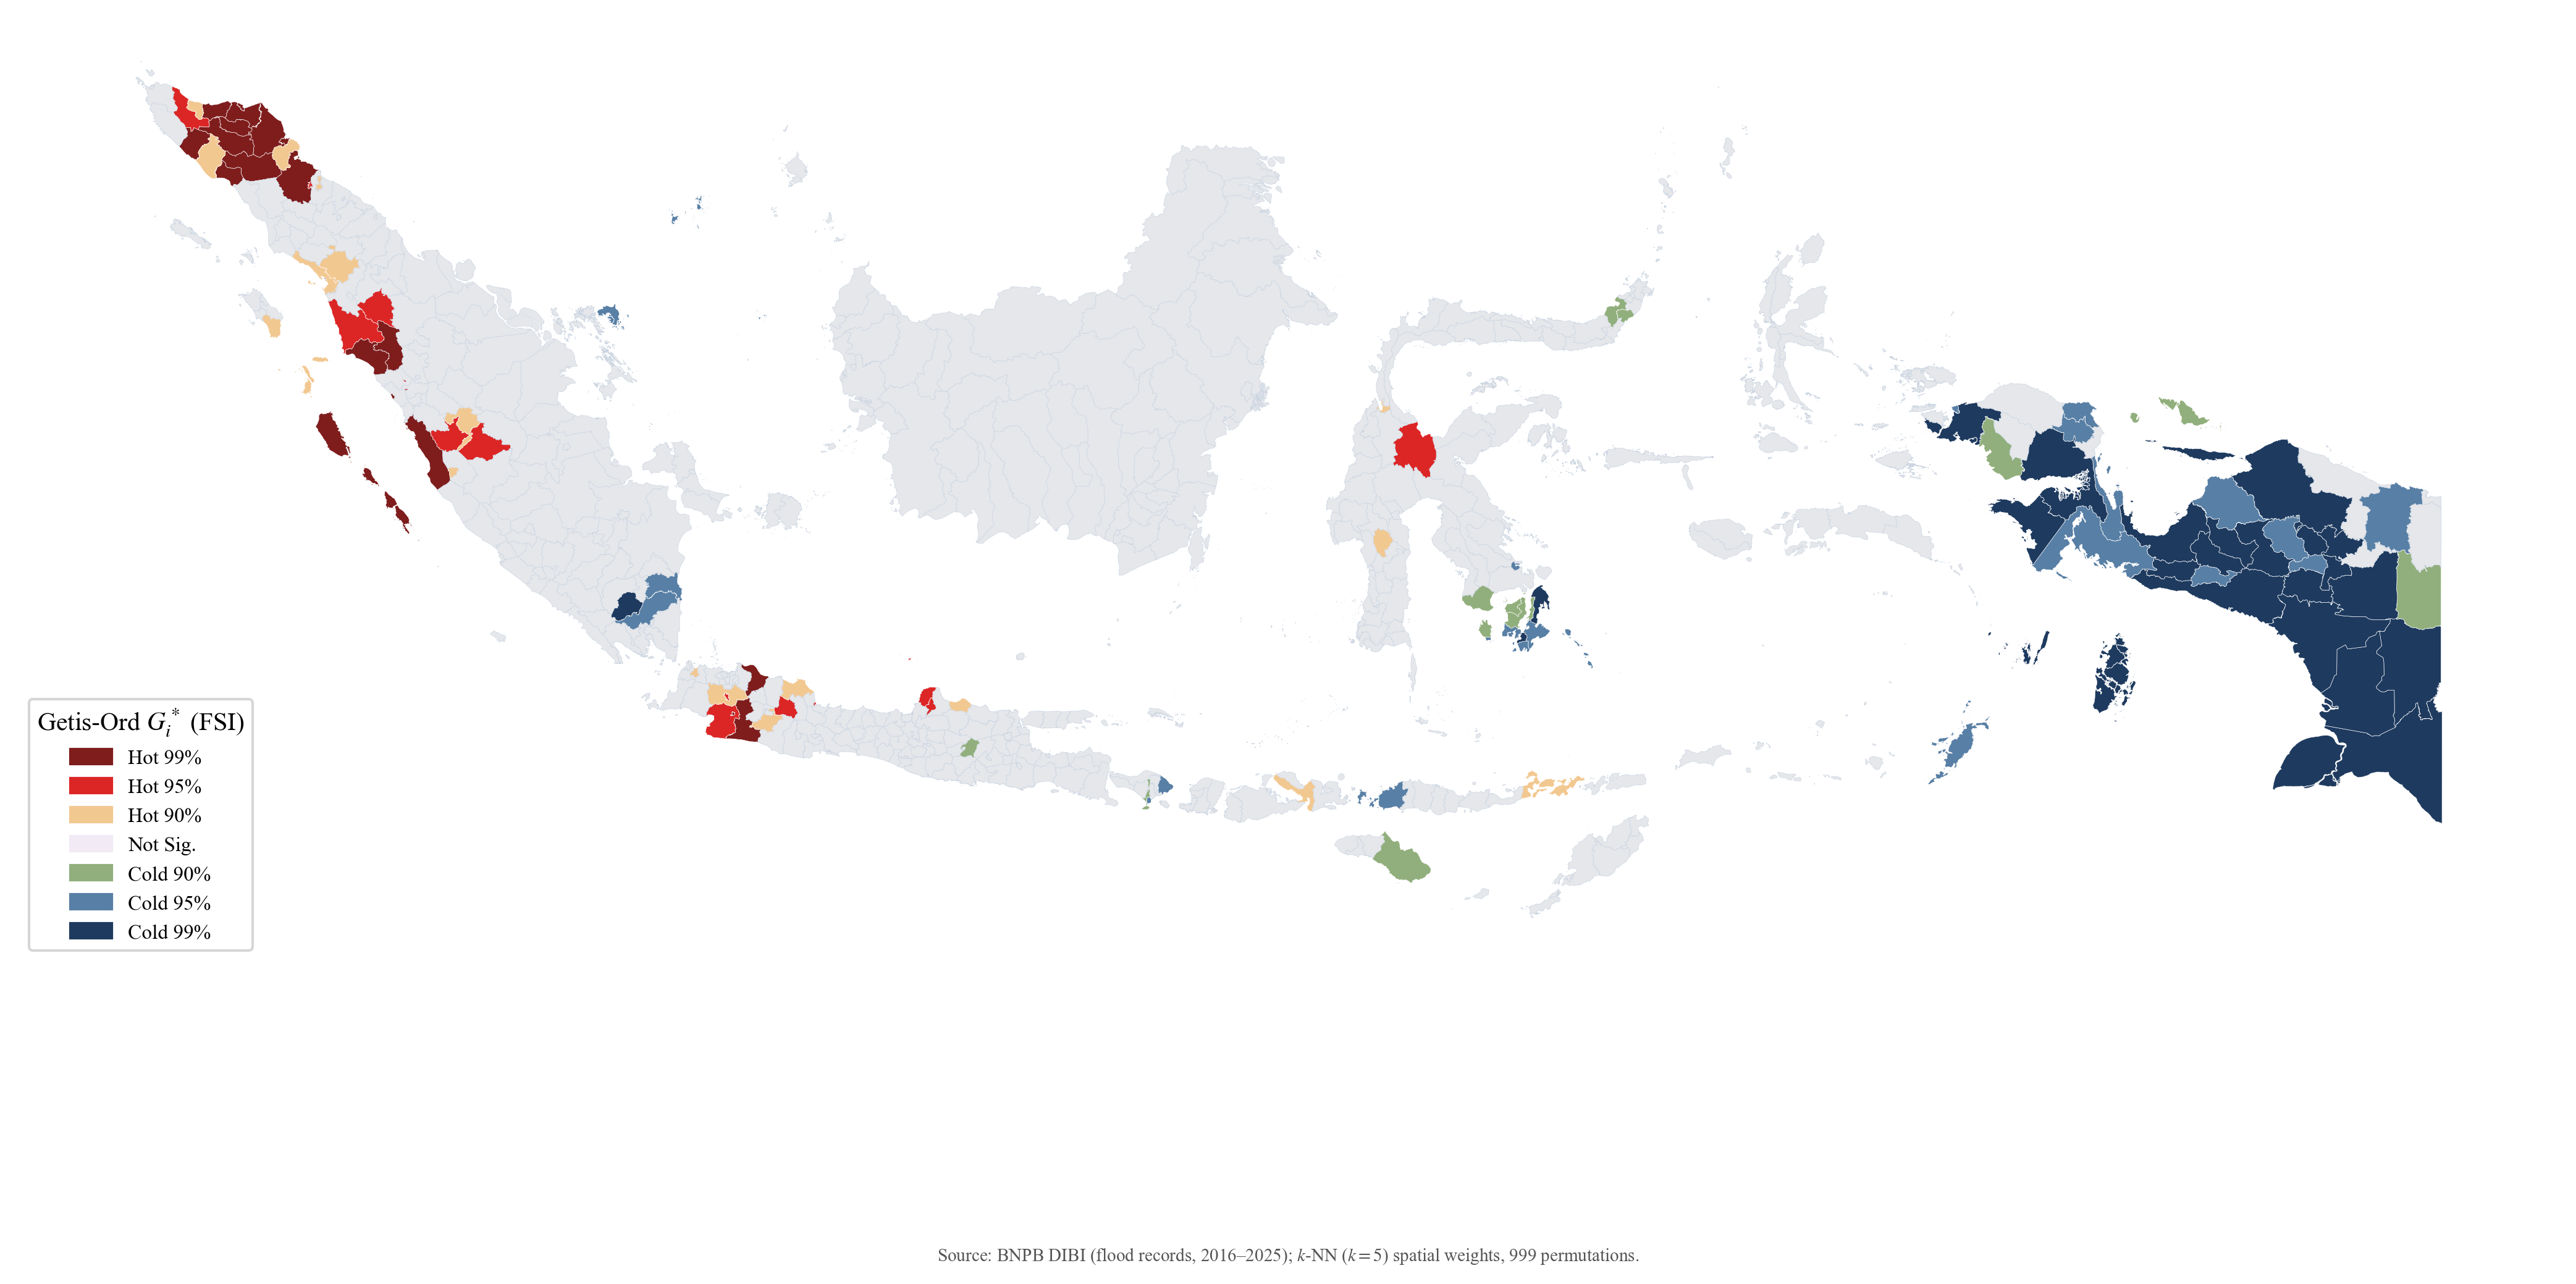

Saved: ..\figures\fig4_gi_hotspot_map.png

Gi* category counts (FSI):
  Hot 99%      20
  Hot 95%      15
  Hot 90%      19
  Not Sig.      0
  Cold 90%     12
  Cold 95%     24
  Cold 99%     26
  TOTAL hot    54
  TOTAL cold   62


In [82]:
# ============================================================================
# STEP 11 — Manuscript figure — Gi* hot-spot / cold-spot map
# ----------------------------------------------------------------------------
# WHERE TO PLACE: at the END of nb6, AFTER the Gi* step that creates the
# `flood` dataframe with columns `gi_cat_FSI` (category) and `gi_z_FSI`
# (z-score). This map colours regencies by their Gi* category, NOT by FSI —
# so it shows WHERE severity clusters spatially, complementing the k-means
# cluster map (which groups by severity profile, spatially blind).
#
# OUTPUT: ../figures/fig4_gi_hotspot_map.png
# ============================================================================
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pandas as pd
import numpy as np
import geopandas as gpd
from pathlib import Path

# --- paths (yours) ---
GPKG_PATH = '../data/processed/2_Kab_Kota_with_BPS.gpkg'
FIG_DIR   = Path('../figures')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- academic styling (matches nb5 cluster map for side-by-side comparison) ---
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif", "Liberation Serif"],
    "font.size": 10, "figure.dpi": 300, "savefig.dpi": 300,
    "mathtext.fontset": "stix",
})

# --- colour scheme: red = hot, blue = cold, pale = not significant ---
HOTSPOT_COLORS = {
    "Hot 99%":  "#7f1d1d",   # dark red
    "Hot 95%":  "#dc2626",   # red
    "Hot 90%":  "#f2c891",   # pale orange
    "Not Sig.": "#f2eaf4",   # near-white
    "Cold 90%": "#91af7c",   # pale green
    "Cold 95%": "#587fa5",   # blue
    "Cold 99%": "#1e3a5f",   # dark blue
}

# --- guards ---
assert "flood" in dir(), "flood dataframe not found — run the Gi* step in nb6 first."
assert "gi_cat_FSI" in flood.columns, "column gi_cat_FSI not found in flood — run the Gi* step first."

# --- load boundaries, clean geometry ---
gdf_geo = gpd.read_file(GPKG_PATH)
gdf_geo["bps_kab_code"] = pd.to_numeric(gdf_geo["bps_kab_code"], errors="coerce").astype("Int64")
gdf_geo["geometry"] = gdf_geo.geometry.buffer(0).simplify(0.001, preserve_topology=True)

# --- merge Gi* categories onto polygons ---
_flood_geo = flood.copy()
_flood_geo["bps_kab_code"] = pd.to_numeric(_flood_geo["bps_kab_code"], errors="coerce").astype("Int64")

# drop duplicate name/prov columns from the geo layer to avoid merge clashes
_dupe_cols = [c for c in ["bps_kab_name", "bps_prov_name"] if c in gdf_geo.columns]
if _dupe_cols:
    gdf_geo = gdf_geo.drop(columns=_dupe_cols)

gmap4 = gdf_geo.merge(
    _flood_geo[["bps_kab_code", "gi_cat_FSI"]], on="bps_kab_code", how="left"
)

# normalise labels (handle "Not Sig" vs "Not Sig." and NaN)
gmap4["gi_cat_FSI"] = gmap4["gi_cat_FSI"].fillna("Not Sig.")
gmap4["gi_cat_FSI"] = gmap4["gi_cat_FSI"].replace({"Not Sig": "Not Sig."})

# --- plot: one layer per category so colours are exact ---
fig4, ax4 = plt.subplots(figsize=(14, 8))
for label, color in HOTSPOT_COLORS.items():
    _sub = gmap4[gmap4["gi_cat_FSI"] == label]
    if not _sub.empty:
        _sub.plot(ax=ax4, color=color, linewidth=0.15, edgecolor="white")

# any category not in the dict → neutral grey (and warn)
_unmatched = gmap4[~gmap4["gi_cat_FSI"].isin(HOTSPOT_COLORS.keys())]
if not _unmatched.empty:
    _unmatched.plot(ax=ax4, color="#e5e7eb", linewidth=0.15, edgecolor="#cbd5e1")
    print(f"  Note: {len(_unmatched)} regencies had an unrecognised gi_cat_FSI "
          f"value: {_unmatched['gi_cat_FSI'].unique()}")

ax4.set_axis_off()

# --- legend ---
legend_handles = [mpatches.Patch(color=c, label=l) for l, c in HOTSPOT_COLORS.items()]
ax4.legend(handles=legend_handles, loc="lower left",
           title="Getis-Ord $G_i^*$ (FSI)", frameon=True, fontsize=8)

# --- source note ---
fig4.text(0.5, -0.02,
          "Source: BNPB DIBI (flood records, 2016\u20132025); "
          "$k$-NN ($k=5$) spatial weights, 999 permutations.",
          ha="center", fontsize=7, color="#555555")

plt.tight_layout()
out_fig4 = FIG_DIR / "fig4_gi_hotspot_map.png"
fig4.savefig(out_fig4, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: {out_fig4}")

# --- quick verification counts (report these in the paper, verified) ---
print("\nGi* category counts (FSI):")
_counts = gmap4["gi_cat_FSI"].value_counts()
for cat in HOTSPOT_COLORS:
    print(f"  {cat:<10} {int(_counts.get(cat, 0)):>4}")
_hot = sum(int(_counts.get(c, 0)) for c in ["Hot 99%", "Hot 95%", "Hot 90%"])
_cold = sum(int(_counts.get(c, 0)) for c in ["Cold 90%", "Cold 95%", "Cold 99%"])
print(f"  {'TOTAL hot':<10} {_hot:>4}")
print(f"  {'TOTAL cold':<10} {_cold:>4}")